# 🛰️ AstroShield — Evolucionar una constelación inteligente

**Algoritmo genético para diseñar una constelación de 8 satélites de observación** que cubra seis regiones prioritarias
de la Tierra, respetando zonas de desechos espaciales y posiciones ocupadas, con visualización en un globo 3D.

| | |
|---|---|
| **Representación** | 8 satélites × (latitud, longitud, altitud) — 24 genes reales |
| **Cobertura** | huella cónica del sensor (semiángulo 30°), región = disco de 300 km muestreado con 49 puntos |
| **Fitness** | Σ peso·(0.70·cobertura + 0.15·redundancia + 0.15·resolución) / Σ pesos, con pesos Alta 3 · Media 2 · Normal 1 |
| **Restricciones** | reglas de factibilidad de Deb + reparación probabilística + separación mínima de 2° |
| **Resultado de referencia** | fitness **0.9174** (cota de referencia 0.9179), 6/6 regiones, 0 violaciones |

> **Cómo usar este notebook:** `Entorno de ejecución → Ejecutar todo` (≈ 5 min en Colab).
> La sección 0 crea el paquete `astroshield` dentro de Colab. No hace falta instalar nada:
> numpy, scipy, pandas, matplotlib y plotly ya vienen en Colab.

**Índice:** 0 Instalación · 1 Modelo · 2 Etapa 1 · 3 Etapa 2 · 4 Globo 3D · 5 Pruebas (E3–E10) · 6 Pruebas unitarias · 7 Laboratorio interactivo · 8 Conclusiones

## 0. Instalación del paquete `astroshield`

Cada celda escribe un módulo del repositorio. Están colapsadas para no estorbar, pero puedes abrirlas para revisar el código.

| Módulo | Responsabilidad |
|---|---|
| `geo.py` | geometría esférica (haversine, rumbos, círculos sobre la esfera) |
| `scenario.py` | datos del problema: regiones, zonas, parámetros y cambios de condiciones |
| `evaluation.py` | modelo de cobertura, restricciones, fitness y criterios de aceptación |
| `ga.py` | algoritmo genético: selección, cruce alineado, mutación, reparación y elitismo |
| `baselines.py` | búsqueda aleatoria y heurística voraz, para comparar |
| `experiments.py` | las pruebas E1–E10 |
| `viz.py` | gráficas, mapa de misión y globo 3D |

In [1]:
import os
os.makedirs('astroshield', exist_ok=True)
os.makedirs('tests', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

In [2]:
%%writefile astroshield/__init__.py
"""AstroShield: evolutionary design of an Earth-observation constellation."""
__version__ = "1.0.0"

Writing astroshield/__init__.py


In [3]:
%%writefile astroshield/geo.py
"""Spherical geometry helpers.

All angles are in degrees unless the name says otherwise. The Earth is a
perfect sphere of radius EARTH_RADIUS_KM (educational model).
"""
from __future__ import annotations

import numpy as np

EARTH_RADIUS_KM = 6371.0


def wrap_lon(lon):
    """Wrap longitude(s) into [-180, 180)."""
    return (np.asarray(lon) + 180.0) % 360.0 - 180.0


def km_to_deg(km):
    """Ground distance (km) -> central angle (deg)."""
    return np.degrees(np.asarray(km) / EARTH_RADIUS_KM)


def deg_to_km(deg):
    """Central angle (deg) -> ground distance (km)."""
    return np.radians(np.asarray(deg)) * EARTH_RADIUS_KM


def to_unit(lat, lon):
    """Lat/lon (deg) -> unit vectors with shape (..., 3)."""
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    cos_lat = np.cos(lat_r)
    return np.stack(
        [cos_lat * np.cos(lon_r), cos_lat * np.sin(lon_r), np.sin(lat_r)], axis=-1
    )


def from_unit(v):
    """Unit (or any non-zero) vectors (..., 3) -> (lat, lon) in degrees."""
    v = np.asarray(v, dtype=float)
    v = v / np.linalg.norm(v, axis=-1, keepdims=True)
    lat = np.degrees(np.arcsin(np.clip(v[..., 2], -1.0, 1.0)))
    lon = np.degrees(np.arctan2(v[..., 1], v[..., 0]))
    return lat, lon


def angular_distance(lat1, lon1, lat2, lon2):
    """Great-circle central angle (deg) using the haversine formula."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = p2 - p1
    dl = np.radians(np.asarray(lon2) - np.asarray(lon1))
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0))))


def initial_bearing(lat1, lon1, lat2, lon2):
    """Initial bearing (deg, clockwise from north) from point 1 to point 2."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dl = np.radians(np.asarray(lon2) - np.asarray(lon1))
    x = np.sin(dl) * np.cos(p2)
    y = np.cos(p1) * np.sin(p2) - np.sin(p1) * np.cos(p2) * np.cos(dl)
    return np.degrees(np.arctan2(x, y)) % 360.0


def destination(lat, lon, bearing, distance):
    """Point reached travelling `distance` (deg) from (lat, lon) along `bearing`."""
    p1 = np.radians(lat)
    l1 = np.radians(lon)
    b = np.radians(bearing)
    d = np.radians(distance)
    p2 = np.arcsin(np.sin(p1) * np.cos(d) + np.cos(p1) * np.sin(d) * np.cos(b))
    l2 = l1 + np.arctan2(
        np.sin(b) * np.sin(d) * np.cos(p1), np.cos(d) - np.sin(p1) * np.sin(p2)
    )
    return np.degrees(p2), wrap_lon(np.degrees(l2))


def circle(lat, lon, radius, n=72):
    """Boundary of a spherical cap as (lats, lons), counter-clockwise, closed."""
    bearings = np.linspace(360.0, 0.0, n + 1)  # decreasing bearing => CCW on a map
    return destination(lat, lon, bearings, radius)


def disk_samples(lat, lon, radius, rings=3):
    """Sample points (N, 2) covering a spherical disk: centre + concentric rings.

    Ring k (1..rings) sits at radius*k/rings and holds 8*k points, so the
    outer ring lies exactly on the region border.
    """
    pts = [(lat, lon)]
    for k in range(1, rings + 1):
        n = 8 * k
        offset = 0.0 if k % 2 else 180.0 / n  # stagger rings
        bearings = offset + np.arange(n) * 360.0 / n
        la, lo = destination(lat, lon, bearings, radius * k / rings)
        pts.extend(zip(la, lo))
    return np.array(pts, dtype=float)


def random_points(rng, n):
    """`n` points uniformly distributed on the sphere -> (lat, lon) arrays."""
    lat = np.degrees(np.arcsin(rng.uniform(-1.0, 1.0, n)))
    lon = rng.uniform(-180.0, 180.0, n)
    return lat, lon


def gaussian_step(rng, lat, lon, sigma):
    """Move each point a 2-D Gaussian step (sigma in deg) on the sphere."""
    lat = np.asarray(lat, dtype=float)
    dx = rng.normal(0.0, sigma, lat.shape)
    dy = rng.normal(0.0, sigma, lat.shape)
    dist = np.hypot(dx, dy)
    bearing = np.degrees(np.arctan2(dx, dy))
    return destination(lat, lon, bearing, dist)

Writing astroshield/geo.py


In [4]:
%%writefile astroshield/scenario.py
"""Problem data: regions to observe, forbidden zones and model parameters.

A Scenario is immutable. Every "change of conditions" (section 3.3 of the
brief) produces a new Scenario via the `with_*` helpers, so previous
configurations can be re-validated against the new one.
"""
from __future__ import annotations

import json
from dataclasses import asdict, dataclass, field, replace
from typing import Tuple

# How the brief's qualitative priorities become numeric weights.
# Alta counts three times a Normal region; Media twice.
PRIORITY_WEIGHTS = {"alta": 3.0, "media": 2.0, "normal": 1.0}


@dataclass(frozen=True)
class Region:
    name: str
    lat: float
    lon: float
    priority: str  # "alta" | "media" | "normal"
    radius_km: float = 300.0

    @property
    def weight(self) -> float:
        return PRIORITY_WEIGHTS[self.priority]


@dataclass(frozen=True)
class Zone:
    """Forbidden cap on the sphere. A satellite whose sub-satellite point lies
    inside the cap (at any altitude) violates it."""

    name: str
    lat: float
    lon: float
    radius_deg: float
    kind: str = "debris"  # "debris" | "occupied"


@dataclass(frozen=True)
class Scenario:
    regions: Tuple[Region, ...]
    zones: Tuple[Zone, ...] = ()
    name: str = "base"
    n_satellites: int = 8
    alt_min_km: float = 500.0
    alt_max_km: float = 2000.0
    sensor_half_angle_deg: float = 30.0
    min_separation_deg: float = 2.0
    coverage_threshold: float = 0.95
    # Fitness weights (sum to 1): single coverage, double coverage, resolution.
    w_coverage: float = 0.70
    w_redundancy: float = 0.15
    w_resolution: float = 0.15
    sample_rings: int = 3
    notes: Tuple[str, ...] = field(default_factory=tuple)

    # --- changes of conditions -------------------------------------------
    def renamed(self, name: str, note: str = "") -> "Scenario":
        notes = self.notes + ((note,) if note else ())
        return replace(self, name=name, notes=notes)

    def with_zone(self, zone: Zone, name: str = None) -> "Scenario":
        return replace(
            self,
            zones=self.zones + (zone,),
            name=name or f"{self.name}+{zone.name}",
            notes=self.notes + (f"nueva zona {zone.name} ({zone.radius_deg}°)",),
        )

    def without_zone(self, zone_name: str, name: str = None) -> "Scenario":
        return replace(
            self,
            zones=tuple(z for z in self.zones if z.name != zone_name),
            name=name or f"{self.name}-{zone_name}",
        )

    def with_priority(self, region_name: str, priority: str, name: str = None) -> "Scenario":
        if priority not in PRIORITY_WEIGHTS:
            raise ValueError(f"unknown priority {priority!r}")
        if region_name not in {r.name for r in self.regions}:
            raise KeyError(region_name)
        regions = tuple(
            replace(r, priority=priority) if r.name == region_name else r for r in self.regions
        )
        return replace(
            self,
            regions=regions,
            name=name or f"{self.name}:{region_name}={priority}",
            notes=self.notes + (f"prioridad {region_name} -> {priority}",),
        )

    def with_params(self, name: str = None, **params) -> "Scenario":
        return replace(self, name=name or self.name, **params)

    @property
    def debris_zones(self):
        return tuple(z for z in self.zones if z.kind == "debris")

    @property
    def occupied_zones(self):
        return tuple(z for z in self.zones if z.kind == "occupied")

    def to_dict(self) -> dict:
        return asdict(self)

    def to_json(self, **kw) -> str:
        return json.dumps(self.to_dict(), ensure_ascii=False, **kw)


REGIONS = (
    Region("Península de Yucatán", 20.5, -89.0, "alta"),
    Region("Amazonía brasileña", -3.5, -62.0, "alta"),
    Region("California", 36.8, -119.4, "media"),
    Region("Sahel", 15.0, 0.0, "media"),
    Region("Japón", 36.0, 138.0, "media"),
    Region("Interior de Australia", -25.0, 133.0, "normal"),
)

DEBRIS_ZONES = (
    Zone("Atlántico Norte", 45.0, -35.0, 12.0, "debris"),
    Zone("Pacífico Sur", -30.0, -120.0, 10.0, "debris"),
    Zone("Polar Norte", 78.0, 30.0, 8.0, "debris"),
)

OCCUPIED_ZONES = (
    Zone("Objeto A", 10.0, 45.0, 5.0, "occupied"),
    Zone("Objeto B", -15.0, 110.0, 5.0, "occupied"),
)


def initial_scenario() -> Scenario:
    """Stage 1: regions only, no spatial restrictions."""
    return Scenario(regions=REGIONS, zones=(), name="etapa1-sin-restricciones")


def default_scenario() -> Scenario:
    """Stage 2: regions + debris zones + occupied positions."""
    return Scenario(regions=REGIONS, zones=DEBRIS_ZONES + OCCUPIED_ZONES, name="base")

Writing astroshield/scenario.py


In [5]:
%%writefile astroshield/evaluation.py
"""Coverage model, constraint checking and fitness.

A configuration is a float array of shape (n_satellites, 3) whose columns
are (latitude deg, longitude deg, altitude km) of each satellite's
sub-satellite point. A population is an array (P, n_satellites, 3).

Coverage model
--------------
Each satellite carries a nadir-pointing sensor with half-angle eta. Its
ground footprint is a spherical cap of central angle

    lambda(h) = asin((R + h) / R * sin(eta)) - eta

(or the horizon angle acos(R / (R + h)) if the sensor sees past it).
Each region is a 300 km disk discretised into sample points; a point is
seen by a satellite when its angular distance to the sub-satellite point
is <= lambda(h). A region is "covered" when the fraction of its points
seen by at least one satellite reaches `coverage_threshold`.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import List

import numpy as np

from .geo import EARTH_RADIUS_KM, angular_distance, deg_to_km, disk_samples, km_to_deg, to_unit
from .scenario import Scenario

FEASIBILITY_TOL = 1e-9


def footprint_half_angle(alt_km, sensor_half_angle_deg):
    """Central angle (deg) of the footprint for altitude(s) `alt_km`."""
    alt_km = np.asarray(alt_km, dtype=float)
    eta = np.radians(sensor_half_angle_deg)
    ratio = (EARTH_RADIUS_KM + alt_km) / EARTH_RADIUS_KM * np.sin(eta)
    horizon = np.arccos(EARTH_RADIUS_KM / (EARTH_RADIUS_KM + alt_km))
    lam = np.where(ratio < 1.0, np.arcsin(np.minimum(ratio, 1.0)) - eta, horizon)
    return np.degrees(np.minimum(lam, horizon))


def resolution_quality(alt_km, alt_min_km, alt_max_km):
    """1.0 at the lowest allowed altitude, 0.0 at the highest (linear)."""
    return 1.0 - (np.asarray(alt_km) - alt_min_km) / (alt_max_km - alt_min_km)


@dataclass
class RegionResult:
    name: str
    priority: str
    weight: float
    coverage: float  # fraction of points seen by >= 1 satellite
    redundancy: float  # fraction of points seen by >= 2 satellites
    resolution: float  # mean best resolution quality over points (0 if unseen)
    score: float
    covered: bool
    satellites: List[int]  # satellites that see at least one point


@dataclass
class Violation:
    satellite: int
    constraint: str  # "debris" | "occupied" | "separation"
    target: str
    distance_deg: float
    limit_deg: float

    @property
    def intrusion_deg(self) -> float:
        return self.limit_deg - self.distance_deg


@dataclass
class Evaluation:
    config: np.ndarray
    fitness: float
    feasible: bool
    violation: float  # total intrusion in degrees (0 when feasible)
    regions: List[RegionResult]
    violations: List[Violation] = field(default_factory=list)

    @property
    def n_covered(self) -> int:
        return sum(r.covered for r in self.regions)

    @property
    def weighted_coverage(self) -> float:
        w = np.array([r.weight for r in self.regions])
        c = np.array([r.coverage for r in self.regions])
        return float((w * c).sum() / w.sum())

    def region_table(self):
        import pandas as pd

        return pd.DataFrame(
            [
                {
                    "región": r.name,
                    "prioridad": r.priority,
                    "peso": r.weight,
                    "cobertura": round(r.coverage, 3),
                    "redundancia": round(r.redundancy, 3),
                    "resolución": round(r.resolution, 3),
                    "score": round(r.score, 3),
                    "cubierta": "sí" if r.covered else "NO",
                    "satélites": ",".join(map(str, r.satellites)) or "-",
                }
                for r in self.regions
            ]
        )

    def satellite_table(self, scenario: Scenario):
        import pandas as pd

        lam = footprint_half_angle(self.config[:, 2], scenario.sensor_half_angle_deg)
        return pd.DataFrame(
            {
                "sat": np.arange(len(self.config)),
                "lat": self.config[:, 0].round(2),
                "lon": self.config[:, 1].round(2),
                "alt_km": self.config[:, 2].round(0),
                "huella_km": deg_to_km(lam).round(0),
            }
        )


class Evaluator:
    """Pre-computes the scenario geometry and evaluates populations fast."""

    def __init__(self, scenario: Scenario):
        self.scenario = scenario
        pts, owner = [], []
        for i, r in enumerate(scenario.regions):
            s = disk_samples(r.lat, r.lon, km_to_deg(r.radius_km), scenario.sample_rings)
            pts.append(s)
            owner.extend([i] * len(s))
        pts = np.vstack(pts)
        self.points = pts
        self.point_owner = np.array(owner)
        self.point_unit = to_unit(pts[:, 0], pts[:, 1])  # (M, 3)
        counts = np.bincount(self.point_owner, minlength=len(scenario.regions))
        self.region_offsets = np.concatenate([[0], np.cumsum(counts)[:-1]])
        self.region_counts = counts
        self.weights = np.array([r.weight for r in scenario.regions])
        if scenario.zones:
            self.zone_unit = to_unit(
                np.array([z.lat for z in scenario.zones]), np.array([z.lon for z in scenario.zones])
            )
            self.zone_radius = np.array([z.radius_deg for z in scenario.zones])
        else:
            self.zone_unit = np.zeros((0, 3))
            self.zone_radius = np.zeros(0)
        self.n_evaluations = 0

    # ------------------------------------------------------------------ batch
    def _region_mean(self, per_point):
        """(P, M) -> (P, R) mean over each region's points."""
        sums = np.add.reduceat(per_point, self.region_offsets, axis=1)
        return sums / self.region_counts

    def evaluate_population(self, pop):
        """Vectorised evaluation of a population (P, S, 3).

        Returns a dict of arrays: fitness (P,), violation (P,), feasible (P,),
        coverage/redundancy/resolution/score (P, R).
        """
        sc = self.scenario
        pop = np.asarray(pop, dtype=float)
        self.n_evaluations += len(pop)
        sat_u = to_unit(pop[..., 0], pop[..., 1])  # (P, S, 3)
        alt = pop[..., 2]
        lam = footprint_half_angle(alt, sc.sensor_half_angle_deg)  # (P, S)

        cos_ang = np.einsum("psk,mk->psm", sat_u, self.point_unit)  # (P, S, M)
        inside = cos_ang >= np.cos(np.radians(lam))[..., None]
        count = inside.sum(axis=1)  # (P, M)
        q = resolution_quality(alt, sc.alt_min_km, sc.alt_max_km)  # (P, S)
        best_q = np.where(inside, q[..., None], 0.0).max(axis=1)  # (P, M)

        cov = self._region_mean((count >= 1).astype(float))
        red = self._region_mean((count >= 2).astype(float))
        res = self._region_mean(best_q)
        score = sc.w_coverage * cov + sc.w_redundancy * red + sc.w_resolution * res
        fitness = (score * self.weights).sum(axis=1) / self.weights.sum()

        violation = np.zeros(len(pop))
        if len(self.zone_radius):
            zang = np.degrees(
                np.arccos(np.clip(np.einsum("psk,zk->psz", sat_u, self.zone_unit), -1, 1))
            )
            violation += np.clip(self.zone_radius - zang, 0, None).sum(axis=(1, 2))
        if sc.min_separation_deg > 0 and pop.shape[1] > 1:
            sang = np.degrees(
                np.arccos(np.clip(np.einsum("psk,pqk->psq", sat_u, sat_u), -1, 1))
            )
            iu = np.triu_indices(pop.shape[1], k=1)
            violation += np.clip(sc.min_separation_deg - sang[:, iu[0], iu[1]], 0, None).sum(axis=1)

        return {
            "fitness": fitness,
            "violation": violation,
            "feasible": violation <= FEASIBILITY_TOL,
            "coverage": cov,
            "redundancy": red,
            "resolution": res,
            "score": score,
            "inside": inside,
        }

    # ----------------------------------------------------------------- single
    def evaluate(self, config) -> Evaluation:
        """Detailed evaluation of one configuration (S, 3)."""
        config = np.asarray(config, dtype=float)
        b = self.evaluate_population(config[None])
        sc = self.scenario
        inside = b["inside"][0]  # (S, M)
        regions = []
        for i, r in enumerate(sc.regions):
            sl = slice(self.region_offsets[i], self.region_offsets[i] + self.region_counts[i])
            sats = [int(s) for s in np.flatnonzero(inside[:, sl].any(axis=1))]
            cov = float(b["coverage"][0, i])
            regions.append(
                RegionResult(
                    name=r.name,
                    priority=r.priority,
                    weight=r.weight,
                    coverage=cov,
                    redundancy=float(b["redundancy"][0, i]),
                    resolution=float(b["resolution"][0, i]),
                    score=float(b["score"][0, i]),
                    covered=cov >= sc.coverage_threshold - 1e-12,
                    satellites=sats,
                )
            )
        return Evaluation(
            config=config.copy(),
            fitness=float(b["fitness"][0]),
            feasible=bool(b["feasible"][0]),
            violation=float(b["violation"][0]),
            regions=regions,
            violations=list_violations(config, sc),
        )


def list_violations(config, scenario: Scenario) -> List[Violation]:
    """Human-readable list of every constraint a configuration breaks."""
    out = []
    lat, lon = config[:, 0], config[:, 1]
    for z in scenario.zones:
        d = angular_distance(lat, lon, z.lat, z.lon)
        for s in np.flatnonzero(d < z.radius_deg):
            out.append(Violation(int(s), z.kind, z.name, float(d[s]), z.radius_deg))
    if scenario.min_separation_deg > 0:
        n = len(config)
        for i in range(n):
            for j in range(i + 1, n):
                d = float(angular_distance(lat[i], lon[i], lat[j], lon[j]))
                if d < scenario.min_separation_deg:
                    out.append(Violation(i, "separation", f"sat {j}", d, scenario.min_separation_deg))
    return out


def min_altitude_for_full_view(radius_km, scenario: Scenario, offset_deg=0.0):
    """Lowest altitude whose footprint covers a disk of `radius_km` whose
    centre is `offset_deg` away from the sub-satellite point (None if none)."""
    need = km_to_deg(radius_km) + offset_deg
    alts = np.arange(scenario.alt_min_km, scenario.alt_max_km + 1e-9, 1.0)
    ok = footprint_half_angle(alts, scenario.sensor_half_angle_deg) >= need
    return float(alts[ok][0]) if ok.any() else None


def reference_upper_bound(scenario: Scenario) -> dict:
    """Optimistic reference value of the fitness (a relaxation).

    Ignores forbidden zones and assumes each region gets its own satellite
    right over its centre at the lowest altitude that sees the whole disk;
    the spare satellites (n_satellites - n_regions) are given to the
    heaviest regions as full redundancy. Valid for this scenario because no
    footprint (max ~11°) can reach two regions at once (min gap ~30°).
    """
    regions = sorted(scenario.regions, key=lambda r: -r.weight)
    spares = max(scenario.n_satellites - len(regions), 0)
    total, detail = 0.0, {}
    for k, r in enumerate(regions):
        h = min_altitude_for_full_view(r.radius_km, scenario)
        if h is None:
            q, cov = 0.0, 0.0
        else:
            q, cov = float(resolution_quality(h, scenario.alt_min_km, scenario.alt_max_km)), 1.0
        red = 1.0 if (k < spares and cov > 0) else 0.0
        s = scenario.w_coverage * cov + scenario.w_redundancy * red + scenario.w_resolution * q
        detail[r.name] = {"alt_km": h, "score": s}
        total += r.weight * s
    return {"fitness": total / sum(r.weight for r in regions), "regions": detail}


def acceptance(ev: Evaluation, scenario: Scenario) -> dict:
    """Team criteria for 'good enough' (see docs/01_definicion_problema.md)."""
    alta = [r for r in ev.regions if r.priority == "alta"]
    # Redundancy is only demanded for as many Alta regions as there are spare
    # satellites (n_satellites - n_regions); asking for more is unattainable.
    spares = max(scenario.n_satellites - len(scenario.regions), 0)
    needed = min(len(alta), spares)
    checks = {
        "C1 válida (sin violaciones)": ev.feasible,
        "C2 todas las regiones cubiertas": ev.n_covered == len(ev.regions),
        f"C3 ≥{needed} regiones Alta con redundancia ≥ 95%": sum(r.redundancy >= 0.95 for r in alta) >= needed,
        "C4 fitness ≥ 90% de la cota de referencia": ev.fitness
        >= 0.90 * reference_upper_bound(scenario)["fitness"],
    }
    checks["ACEPTADA"] = all(checks.values())
    return checks

Writing astroshield/evaluation.py


In [6]:
%%writefile astroshield/ga.py
"""Real-coded genetic algorithm for the constellation problem.

Genome: (n_satellites, 3) array of (lat, lon, alt_km).

Loop per generation:
  1. rank population (constraint handling: Deb's feasibility rules by default)
  2. elitism: copy the best `elite_size` individuals unchanged
  3. tournament selection of parents
  4. aligned crossover: parent B's satellites are matched to parent A's with
     the Hungarian algorithm before mixing, because the satellite order in
     the genome is arbitrary (permutation symmetry)
  5. mutation: Gaussian step on the sphere + altitude jitter, both with
     exponentially decaying sigma; rare random relocation keeps exploring
  6. repair (probabilistic): satellites inside a forbidden zone are pushed
     to its border along the great circle from the zone centre
"""
from __future__ import annotations

import time
from dataclasses import asdict, dataclass, field
from typing import Callable, List, Optional

import numpy as np
from scipy.optimize import linear_sum_assignment

from .evaluation import Evaluation, Evaluator
from .geo import angular_distance, destination, from_unit, gaussian_step, initial_bearing, random_points, to_unit
from .scenario import Scenario

CONSTRAINT_MODES = ("deb", "penalty", "none")


@dataclass
class GAConfig:
    population_size: int = 120
    generations: int = 400
    tournament_size: int = 4
    crossover_rate: float = 0.9
    blend_rate: float = 0.3  # per-satellite chance of arithmetic (vs. swap) crossover
    align_crossover: bool = True  # match satellites before crossover
    mutation_rate: float = 0.15  # per-satellite
    sigma_start_deg: float = 12.0
    sigma_end_deg: float = 0.05
    alt_sigma_start_km: float = 250.0
    alt_sigma_end_km: float = 2.0
    reset_rate: float = 0.02  # per-satellite random relocation
    repair_rate: float = 0.3  # per-child probability of applying repair
    elite_size: int = 4
    constraint_handling: str = "deb"  # "deb" | "penalty" | "none"
    penalty_factor: float = 0.05  # fitness lost per degree of intrusion
    patience: Optional[int] = None  # stop after N gens without improvement

    def __post_init__(self):
        if self.constraint_handling not in CONSTRAINT_MODES:
            raise ValueError(f"constraint_handling must be one of {CONSTRAINT_MODES}")
        if not 0 <= self.elite_size < self.population_size:
            raise ValueError("elite_size must be smaller than population_size")

    def to_dict(self):
        return asdict(self)


@dataclass
class GAResult:
    scenario: Scenario
    config: GAConfig
    seed: int
    best: np.ndarray
    best_eval: Evaluation
    initial_best: np.ndarray
    initial_eval: Evaluation
    history: List[dict]
    final_population: np.ndarray
    evaluations: int
    elapsed_s: float
    stop_reason: str
    snapshots: dict = field(default_factory=dict)  # generation -> best config

    @property
    def found_feasible(self) -> bool:
        return self.best_eval.feasible

    def history_frame(self):
        import pandas as pd

        return pd.DataFrame(self.history)


# ---------------------------------------------------------------- operators
def random_population(rng, scenario: Scenario, n: int) -> np.ndarray:
    s = scenario.n_satellites
    lat, lon = random_points(rng, n * s)
    alt = rng.uniform(scenario.alt_min_km, scenario.alt_max_km, n * s)
    return np.stack([lat, lon, alt], axis=-1).reshape(n, s, 3)


def rank_values(batch: dict, mode: str, penalty: float) -> np.ndarray:
    """Higher is better. Deb: any feasible beats any infeasible; infeasible
    ones are ordered by total violation."""
    f, v = batch["fitness"], batch["violation"]
    if mode == "none":
        return f.copy()
    if mode == "penalty":
        return f - penalty * v
    return np.where(batch["feasible"], f, -1.0 - v)


def align(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Reorder b's satellites so b[i] is the satellite closest to a[i]."""
    cost = angular_distance(a[:, None, 0], a[:, None, 1], b[None, :, 0], b[None, :, 1])
    _, cols = linear_sum_assignment(cost)
    return b[cols]


def crossover(rng, a, b, blend_rate, aligned=True):
    if aligned:
        b = align(a, b)
    s = len(a)
    c1, c2 = a.copy(), b.copy()
    swap = rng.random(s) < 0.5
    c1[swap], c2[swap] = b[swap], a[swap]
    blend = rng.random(s) < blend_rate
    if blend.any():
        w = rng.random(blend.sum())[:, None]
        ua, ub = to_unit(a[blend, 0], a[blend, 1]), to_unit(b[blend, 0], b[blend, 1])
        for child, ww in ((c1, w), (c2, 1 - w)):
            v = ww * ua + (1 - ww) * ub
            ok = np.linalg.norm(v, axis=1) > 1e-6  # skip antipodal pairs
            lat, lon = from_unit(np.where(ok[:, None], v, ua))
            idx = np.flatnonzero(blend)
            child[idx, 0], child[idx, 1] = lat, lon
            child[idx, 2] = ww[:, 0] * a[blend, 2] + (1 - ww[:, 0]) * b[blend, 2]
    return c1, c2


def reflect_altitude(alt, lo, hi):
    span = hi - lo
    x = np.mod(alt - lo, 2 * span)
    return lo + np.where(x > span, 2 * span - x, x)


def mutate(rng, ind, scenario, rate, sigma_deg, alt_sigma, reset_rate):
    s = len(ind)
    m = rng.random(s) < rate
    if m.any():
        lat, lon = gaussian_step(rng, ind[m, 0], ind[m, 1], sigma_deg)
        ind[m, 0], ind[m, 1] = lat, lon
        ind[m, 2] = reflect_altitude(
            ind[m, 2] + rng.normal(0, alt_sigma, m.sum()), scenario.alt_min_km, scenario.alt_max_km
        )
    r = rng.random(s) < reset_rate
    if r.any():
        lat, lon = random_points(rng, r.sum())
        ind[r, 0], ind[r, 1] = lat, lon
        ind[r, 2] = rng.uniform(scenario.alt_min_km, scenario.alt_max_km, r.sum())
    return ind


def repair(rng, ind, scenario: Scenario, margin_deg=0.25, max_iter=4):
    """Push satellites out of forbidden zones (in place). Zones may overlap,
    so the push is repeated a few times; leftovers are left to selection."""
    for _ in range(max_iter):
        moved = False
        for z in scenario.zones:
            d = angular_distance(ind[:, 0], ind[:, 1], z.lat, z.lon)
            bad = np.flatnonzero(d < z.radius_deg)
            for i in bad:
                if d[i] < 1e-6:
                    bearing = rng.uniform(0, 360)
                else:
                    bearing = initial_bearing(z.lat, z.lon, ind[i, 0], ind[i, 1])
                ind[i, 0], ind[i, 1] = destination(z.lat, z.lon, bearing, z.radius_deg + margin_deg)
                moved = True
        if not moved:
            break
    return ind


def diversity(rng, pop, n_pairs=12):
    """Mean angular distance between aligned satellites of random pairs."""
    if len(pop) < 2:
        return 0.0
    out = []
    for _ in range(n_pairs):
        i, j = rng.choice(len(pop), 2, replace=False)
        b = align(pop[i], pop[j])
        out.append(angular_distance(pop[i][:, 0], pop[i][:, 1], b[:, 0], b[:, 1]).mean())
    return float(np.mean(out))


# --------------------------------------------------------------------- main
def run_ga(
    scenario: Scenario,
    config: GAConfig = None,
    seed: int = 0,
    initial_population: np.ndarray = None,
    snapshot_every: int = 0,
    callback: Callable[[dict], None] = None,
) -> GAResult:
    """Run the GA and return the best configuration plus full history."""
    cfg = config or GAConfig()
    rng = np.random.default_rng(seed)
    ev = Evaluator(scenario)
    p = cfg.population_size

    pop = random_population(rng, scenario, p)
    if initial_population is not None:  # warm start (change of conditions)
        seedpop = np.asarray(initial_population, dtype=float)[:p]
        pop[: len(seedpop)] = seedpop

    t0 = time.perf_counter()
    batch = ev.evaluate_population(pop)
    rank = rank_values(batch, cfg.constraint_handling, cfg.penalty_factor)
    i0 = int(np.argmax(rank))
    initial_best = pop[i0].copy()
    best, best_rank = pop[i0].copy(), rank[i0]
    history, snapshots = [], {0: initial_best.copy()}
    stale, stop_reason = 0, "generaciones completadas"

    def log(gen, sigma, alt_sigma):
        feas = batch["feasible"]
        f = batch["fitness"]
        row = {
            "generation": gen,
            "best_rank": float(rank.max()),
            "best_fitness": float(f[feas].max()) if feas.any() else np.nan,
            "mean_fitness": float(f.mean()),
            "std_fitness": float(f.std()),
            "worst_fitness": float(f.min()),
            "feasible_ratio": float(feas.mean()),
            "mean_violation": float(batch["violation"].mean()),
            "best_so_far_rank": float(best_rank),
            "regions_covered_best": int(
                (batch["coverage"][int(np.argmax(rank))] >= scenario.coverage_threshold - 1e-12).sum()
            ),
            "diversity_deg": diversity(rng, pop),
            "sigma_deg": float(sigma),
            "alt_sigma_km": float(alt_sigma),
            "evaluations": ev.n_evaluations,
        }
        history.append(row)
        if callback:
            callback(row)

    log(0, cfg.sigma_start_deg, cfg.alt_sigma_start_km)
    for gen in range(1, cfg.generations + 1):
        t = (gen - 1) / max(cfg.generations - 1, 1)
        sigma = cfg.sigma_start_deg * (cfg.sigma_end_deg / cfg.sigma_start_deg) ** t
        alt_sigma = cfg.alt_sigma_start_km * (cfg.alt_sigma_end_km / cfg.alt_sigma_start_km) ** t

        order = np.argsort(-rank)
        children = [pop[i].copy() for i in order[: cfg.elite_size]]
        while len(children) < p:
            cand = rng.integers(0, p, size=(2, cfg.tournament_size))
            pa, pb = (pop[c[np.argmax(rank[c])]] for c in cand)
            if rng.random() < cfg.crossover_rate:
                c1, c2 = crossover(rng, pa, pb, cfg.blend_rate, cfg.align_crossover)
            else:
                c1, c2 = pa.copy(), pb.copy()
            for c in (c1, c2):
                mutate(rng, c, scenario, cfg.mutation_rate, sigma, alt_sigma, cfg.reset_rate)
                if cfg.constraint_handling != "none" and rng.random() < cfg.repair_rate:
                    repair(rng, c, scenario)
                children.append(c)
        pop = np.array(children[:p])
        batch = ev.evaluate_population(pop)
        rank = rank_values(batch, cfg.constraint_handling, cfg.penalty_factor)

        i = int(np.argmax(rank))
        if rank[i] > best_rank + 1e-9:
            best, best_rank, stale = pop[i].copy(), rank[i], 0
        else:
            stale += 1
        log(gen, sigma, alt_sigma)
        if snapshot_every and gen % snapshot_every == 0:
            snapshots[gen] = best.copy()
        if cfg.patience and stale >= cfg.patience:
            stop_reason = f"estancamiento ({cfg.patience} generaciones sin mejora)"
            break

    snapshots[history[-1]["generation"]] = best.copy()
    return GAResult(
        scenario=scenario,
        config=cfg,
        seed=seed,
        best=best,
        best_eval=ev.evaluate(best),
        initial_best=initial_best,
        initial_eval=ev.evaluate(initial_best),
        history=history,
        final_population=pop,
        evaluations=ev.n_evaluations,
        elapsed_s=time.perf_counter() - t0,
        stop_reason=stop_reason,
        snapshots=snapshots,
    )

Writing astroshield/ga.py


In [7]:
%%writefile astroshield/baselines.py
"""Reference methods to prove the GA is better than trivial alternatives."""
from __future__ import annotations

import numpy as np

from .evaluation import Evaluator
from .ga import random_population, rank_values
from .geo import destination
from .scenario import Scenario


def random_search(scenario: Scenario, n_evaluations: int, seed: int = 0, batch: int = 2000):
    """Best of `n_evaluations` uniformly random configurations (Deb ranking).
    Returns (best_config, best_so_far_fitness_curve)."""
    rng = np.random.default_rng(seed)
    ev = Evaluator(scenario)
    best, best_rank, curve = None, -np.inf, []
    done = 0
    while done < n_evaluations:
        n = min(batch, n_evaluations - done)
        pop = random_population(rng, scenario, n)
        b = ev.evaluate_population(pop)
        r = rank_values(b, "deb", 0.0)
        i = int(np.argmax(r))
        if r[i] > best_rank:
            best, best_rank = pop[i].copy(), r[i]
        done += n
        curve.append((done, float(best_rank)))
    return best, curve


def greedy_placement(scenario: Scenario, alt_step_km: float = 50.0):
    """Constructive heuristic: add satellites one by one, each time choosing
    the feasible candidate (around region centres x altitude grid) with the
    largest fitness gain. Mimics what a human designer would do."""
    ev = Evaluator(scenario)
    alts = np.arange(scenario.alt_min_km, scenario.alt_max_km + 1e-9, alt_step_km)
    cands = []
    for r in scenario.regions:
        pts = [(r.lat, r.lon)]
        for dist in (1.0, 2.0, 3.5, 5.0, 7.0):
            bearings = np.arange(0, 360, 45.0)
            la, lo = destination(r.lat, r.lon, bearings, dist)
            pts.extend(zip(la, lo))
        for la, lo in pts:
            for h in alts:
                cands.append((la, lo, h))
    cands = np.array(cands)

    chosen = np.zeros((0, 3))
    for _ in range(scenario.n_satellites):
        pop = np.concatenate(
            [np.repeat(chosen[None], len(cands), axis=0), cands[:, None, :]], axis=1
        )
        sc_part = scenario.with_params(n_satellites=pop.shape[1])
        part = Evaluator(sc_part)
        b = part.evaluate_population(pop)
        r = rank_values(b, "deb", 0.0)
        chosen = pop[int(np.argmax(r))]
    return chosen, ev.evaluate(chosen)

Writing astroshield/baselines.py


In [8]:
%%writefile astroshield/experiments.py
"""Reproducible experiments behind Entregables 3 and 4.

Every function returns plain data (dicts / DataFrames / GAResult) so the
notebook can display it and tools/run_experiments.py can store it as JSON.
"""
from __future__ import annotations

from dataclasses import replace

import numpy as np
import pandas as pd
from scipy import stats

from .baselines import greedy_placement, random_search
from .evaluation import Evaluator, acceptance, reference_upper_bound
from .ga import GAConfig, GAResult, align, run_ga
from .geo import angular_distance
from .scenario import Scenario, Zone, default_scenario, initial_scenario


# ----------------------------------------------------------------- helpers
def convergence_generation(result: GAResult, frac: float = 0.99):
    """First generation whose best-so-far reaches `frac` of the final value."""
    curve = np.array([h["best_so_far_rank"] for h in result.history])
    final = curve[-1]
    if final <= 0:
        return None
    return int(np.argmax(curve >= frac * final))


def first_full_coverage_generation(result: GAResult):
    n = len(result.scenario.regions)
    for h in result.history:
        if h["regions_covered_best"] == n and h["feasible_ratio"] > 0 and not np.isnan(h["best_fitness"]):
            return h["generation"]
    return None


def summarize(result: GAResult) -> dict:
    ev, sc = result.best_eval, result.scenario
    return {
        "scenario": sc.name,
        "seed": result.seed,
        "fitness": round(ev.fitness, 4),
        "initial_fitness": round(result.initial_eval.fitness, 4),
        "feasible": ev.feasible,
        "violation_deg": round(ev.violation, 3),
        "regions_covered": ev.n_covered,
        "weighted_coverage": round(ev.weighted_coverage, 4),
        "accepted": acceptance(ev, sc)["ACEPTADA"],
        "convergence_gen": convergence_generation(result),
        "full_coverage_gen": first_full_coverage_generation(result),
        "generations": result.history[-1]["generation"],
        "evaluations": result.evaluations,
        "time_s": round(result.elapsed_s, 2),
        "bound": round(reference_upper_bound(sc)["fitness"], 4),
    }


def solution_distance(a, b) -> float:
    """Mean angular distance (deg) between satellites after optimal matching."""
    b = align(a, b)
    return float(angular_distance(a[:, 0], a[:, 1], b[:, 0], b[:, 1]).mean())


def zone_margins(config, scenario: Scenario) -> pd.DataFrame:
    """For each zone: distance of the closest satellite and its margin."""
    rows = []
    for z in scenario.zones:
        d = angular_distance(config[:, 0], config[:, 1], z.lat, z.lon)
        rows.append(
            {
                "zona": z.name,
                "tipo": z.kind,
                "radio_deg": z.radius_deg,
                "sat_más_cercano": int(d.argmin()),
                "distancia_deg": round(float(d.min()), 2),
                "margen_deg": round(float(d.min() - z.radius_deg), 2),
                "respeta": bool(d.min() >= z.radius_deg),
            }
        )
    return pd.DataFrame(rows)


# ------------------------------------------------------------ experiments
def e1_initial(cfg: GAConfig = None, seed: int = 0) -> GAResult:
    """Stage 1: no spatial restrictions."""
    return run_ga(initial_scenario(), cfg, seed=seed, snapshot_every=25)


def e2_base(cfg: GAConfig = None, seed: int = 0) -> GAResult:
    """Stage 2 reference run (all restrictions) used by E2, E3, E4, E8, E9."""
    return run_ga(default_scenario(), cfg, seed=seed, snapshot_every=25)


def e3_e4_constraint_audit(results) -> pd.DataFrame:
    """Margins of every best solution to every zone, over many runs."""
    frames = []
    for r in results:
        df = zone_margins(r.best, r.scenario)
        df.insert(0, "seed", r.seed)
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def e4_object_near_region(cfg: GAConfig = None, seed: int = 0) -> GAResult:
    """Occupied position moved next to the Sahel (2° from its centre)."""
    sc = default_scenario().without_zone("Objeto A").with_zone(
        Zone("Objeto A (reubicado)", 15.0, 2.0, 5.0, "occupied"), name="objeto-junto-al-Sahel"
    )
    return run_ga(sc, cfg, seed=seed)


def reduced_space_scenarios():
    base = default_scenario()
    r1 = base.with_zone(Zone("Desechos Golfo de México", 23.0, -90.0, 6.0), name="R1 +zona sobre Yucatán")
    r2 = r1.with_params(name="R2 R1 + techo 1200 km", alt_max_km=1200.0)
    r3 = r2.with_zone(Zone("Desechos Pacífico Norte", 40.0, 140.0, 5.0), name="R3 R2 + zona sobre Japón")
    return [base.renamed("R0 base"), r1, r2, r3]


def e5_reduced_space(cfg: GAConfig = None, seed: int = 0):
    """Progressively shrink the usable space. Also runs R1 *without*
    constraint handling to show what the restrictions prevent."""
    results = [run_ga(sc, cfg, seed=seed) for sc in reduced_space_scenarios()]
    unconstrained = run_ga(
        reduced_space_scenarios()[1], replace(cfg or GAConfig(), constraint_handling="none"), seed=seed
    )
    return results, unconstrained


def infeasible_scenarios():
    base = default_scenario()
    return {
        "I1 Amazonía inalcanzable": base.with_zone(
            Zone("Bloqueo Amazonía", -3.5, -62.0, 15.0), name="I1 Amazonía inalcanzable"
        ),
        "I2 solo 5 satélites": base.with_params(name="I2 solo 5 satélites", n_satellites=5),
        "I3 separación 80° imposible": base.with_params(
            name="I3 separación 80° imposible", min_separation_deg=80.0
        ),
    }


def e6_infeasible(cfg: GAConfig = None, seed: int = 0):
    return {k: run_ga(sc, cfg, seed=seed) for k, sc in infeasible_scenarios().items()}


def e7_variation(cfg: GAConfig = None, seeds=range(10)):
    """Repeated runs + baselines with the same evaluation budget."""
    sc = default_scenario()
    runs = [run_ga(sc, cfg, seed=s) for s in seeds]
    table = pd.DataFrame([summarize(r) for r in runs])
    budget = runs[0].evaluations
    rnd = [random_search(sc, budget, seed=1000 + s)[1][-1][1] for s in seeds]
    _, greedy_ev = greedy_placement(sc)
    ga_f = table["fitness"].to_numpy()
    mw = stats.mannwhitneyu(ga_f, rnd, alternative="greater")
    n = len(runs)
    dist = np.full((n, n), 0.0)
    for i in range(n):
        for j in range(i + 1, n):
            dist[i, j] = dist[j, i] = solution_distance(runs[i].best, runs[j].best)
    iu = np.triu_indices(n, 1)
    summary = {
        "n_runs": n,
        "budget_evaluations": int(budget),
        "ga_mean": float(ga_f.mean()),
        "ga_std": float(ga_f.std(ddof=1)) if n > 1 else 0.0,
        "ga_min": float(ga_f.min()),
        "ga_max": float(ga_f.max()),
        "ga_cv_percent": float(100 * ga_f.std(ddof=1) / ga_f.mean()) if n > 1 else 0.0,
        "ga_accepted": int(table["accepted"].sum()),
        "random_mean": float(np.mean(rnd)),
        "random_max": float(np.max(rnd)),
        "greedy": float(greedy_ev.fitness),
        "bound": float(reference_upper_bound(sc)["fitness"]),
        "mannwhitney_p_ga_gt_random": float(mw.pvalue),
        "solution_distance_mean_deg": float(dist[iu].mean()) if n > 1 else 0.0,
        "solution_distance_max_deg": float(dist[iu].max()) if n > 1 else 0.0,
    }
    return runs, table, summary, rnd, dist


def failure_analysis(config, scenario: Scenario) -> pd.DataFrame:
    """N-1: what is lost if each satellite fails."""
    ev_full = Evaluator(scenario).evaluate(config)
    sc_less = scenario.with_params(n_satellites=len(config) - 1)
    ev = Evaluator(sc_less)
    rows = []
    for s in range(len(config)):
        e = ev.evaluate(np.delete(config, s, axis=0))
        lost = [r.name for r, f in zip(e.regions, ev_full.regions) if f.covered and not r.covered]
        rows.append(
            {
                "satélite_fallado": s,
                "fitness": round(e.fitness, 4),
                "cobertura_ponderada": round(e.weighted_coverage, 4),
                "regiones_cubiertas": e.n_covered,
                "regiones_perdidas": ", ".join(lost) or "ninguna",
            }
        )
    return pd.DataFrame(rows)


def e8_robustness(base: GAResult, cfg: GAConfig = None, seed: int = 0):
    """Own test: value of the redundancy term under satellite failure."""
    no_red_sc = default_scenario().with_params(
        name="sin término de redundancia", w_coverage=0.80, w_redundancy=0.0, w_resolution=0.20
    )
    no_red = run_ga(no_red_sc, cfg, seed=seed)
    sc = default_scenario()
    return {
        "con_redundancia": failure_analysis(base.best, sc),
        "sin_redundancia": failure_analysis(no_red.best, sc),
        "run_sin_redundancia": no_red,
    }


def revalidate(config, old: Scenario, new: Scenario) -> dict:
    """Is a previous configuration still valid / good under new conditions?"""
    a, b = Evaluator(old).evaluate(config), Evaluator(new).evaluate(config)
    return {
        "válida_antes": a.feasible,
        "válida_ahora": b.feasible,
        "fitness_antes": round(a.fitness, 4),
        "fitness_ahora": round(b.fitness, 4),
        "regiones_cubiertas_ahora": b.n_covered,
        "violaciones": [f"sat {v.satellite} en {v.target} ({v.distance_deg:.2f}° < {v.limit_deg}°)" for v in b.violations],
        "aceptada_ahora": acceptance(b, new)["ACEPTADA"],
    }


def e9_change_of_conditions(base: GAResult, cfg: GAConfig = None, seed: int = 0):
    """Section 3.3: priority change and a zone that suddenly becomes unavailable."""
    cfg = cfg or GAConfig()
    old = base.scenario
    out = {}
    # (a) Australia becomes high priority.
    sc_a = old.with_priority("Interior de Australia", "alta", name="C1 Australia -> Alta")
    out["prioridad"] = {
        "scenario": sc_a,
        "revalidación": revalidate(base.best, old, sc_a),
        "reoptimizado": run_ga(sc_a, cfg, seed=seed, initial_population=base.final_population),
    }
    # (b) New debris zone exactly where the satellite observing Japan sits.
    japan = next(r for r in base.best_eval.regions if r.name == "Japón")
    s = japan.satellites[0]
    lat, lon = base.best[s, 0], base.best[s, 1]
    sc_b = old.with_zone(Zone("Desechos nuevos", float(lat), float(lon), 3.0), name="C2 nueva zona sobre Japón")
    short = replace(cfg, generations=min(cfg.generations, 150))
    out["zona_nueva"] = {
        "scenario": sc_b,
        "revalidación": revalidate(base.best, old, sc_b),
        "warm": run_ga(sc_b, short, seed=seed, initial_population=base.final_population),
        "cold": run_ga(sc_b, short, seed=seed),
    }
    return out


ABLATIONS = {
    "configuración final": {},
    "sin alineación en cruce": {"align_crossover": False},
    "sin reparación": {"repair_rate": 0.0},
    "sin elitismo": {"elite_size": 0},
    "mutación alta (0.5)": {"mutation_rate": 0.5},
    "penalización en vez de Deb": {"constraint_handling": "penalty"},
    "población 40": {"population_size": 40},
}


def e10_ablation(cfg: GAConfig = None, seeds=range(3), scenario: Scenario = None):
    """Effect of each operator / parameter choice on the final quality."""
    cfg = cfg or GAConfig()
    sc = scenario or reduced_space_scenarios()[1]  # constraints actually bind here
    rows = []
    for name, change in ABLATIONS.items():
        for s in seeds:
            r = run_ga(sc, replace(cfg, **change), seed=s)
            rows.append(
                {
                    "variante": name,
                    "seed": s,
                    "fitness": r.best_eval.fitness,
                    "válida": r.best_eval.feasible,
                    "conv_gen": convergence_generation(r),
                }
            )
    df = pd.DataFrame(rows)
    agg = (
        df.groupby("variante", sort=False)
        .agg(fitness_media=("fitness", "mean"), fitness_std=("fitness", "std"),
             válidas=("válida", "sum"), conv_gen_media=("conv_gen", "mean"))
        .round(4)
        .reset_index()
    )
    return df, agg

Writing astroshield/experiments.py


In [9]:
%%writefile astroshield/viz.py
"""Visualisation: analysis charts (matplotlib) and the interactive 3D globe.

The globe is a self-contained HTML page built with globe.gl (WebGL). It is
generated from the *actual* run data (scenario + evaluated configurations),
so what you see is exactly what the algorithm produced.
"""
from __future__ import annotations

import json

import matplotlib.pyplot as plt
import numpy as np

from .evaluation import Evaluator, footprint_half_angle
from .geo import EARTH_RADIUS_KM, circle, deg_to_km, km_to_deg
from .scenario import Scenario

# AstroShield palette (custom, dark "mission control" theme).
PALETTE = {
    "bg": "#0B1026",
    "panel": "#131B3D",
    "grid": "#26305C",
    "text": "#E6ECFF",
    "muted": "#8D97C9",
    "final": "#22D3EE",  # final constellation
    "initial": "#A78BFA",  # initial constellation
    "covered": "#34D399",
    "uncovered": "#F87171",
    "debris": "#FB923C",
    "occupied": "#F472B6",
    "mean": "#FACC15",
}
SERIES = ["#22D3EE", "#FACC15", "#34D399", "#F472B6", "#A78BFA", "#FB923C", "#60A5FA", "#F87171"]


def apply_theme():
    plt.rcParams.update(
        {
            "figure.facecolor": PALETTE["bg"],
            "axes.facecolor": PALETTE["panel"],
            "axes.edgecolor": PALETTE["grid"],
            "axes.labelcolor": PALETTE["text"],
            "axes.titlecolor": PALETTE["text"],
            "axes.titleweight": "bold",
            "axes.grid": True,
            "grid.color": PALETTE["grid"],
            "grid.linewidth": 0.6,
            "xtick.color": PALETTE["muted"],
            "ytick.color": PALETTE["muted"],
            "text.color": PALETTE["text"],
            "legend.facecolor": PALETTE["panel"],
            "legend.edgecolor": PALETTE["grid"],
            "axes.prop_cycle": plt.cycler(color=SERIES),
            "figure.dpi": 110,
            "savefig.facecolor": PALETTE["bg"],
            "savefig.bbox": "tight",
            "font.size": 10,
        }
    )


# ------------------------------------------------------------------ charts
def plot_evolution(result, title=None):
    """Best / mean / spread of fitness, feasibility and diversity per generation."""
    h = result.history_frame()
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, height_ratios=[2.2, 1])
    g = h["generation"]
    ax1.fill_between(g, h["mean_fitness"] - h["std_fitness"], h["mean_fitness"] + h["std_fitness"],
                     color=PALETTE["mean"], alpha=0.15, label="media ± desv. estándar")
    ax1.plot(g, h["mean_fitness"], color=PALETTE["mean"], lw=1.4, label="fitness media")
    ax1.plot(g, h["best_fitness"], color=PALETTE["final"], lw=2.2, label="mejor válida de la generación")
    ax1.plot(g, h["worst_fitness"], color=PALETTE["muted"], lw=0.8, ls=":", label="peor")
    from .evaluation import reference_upper_bound

    bound = reference_upper_bound(result.scenario)["fitness"]
    ax1.axhline(bound, color=PALETTE["covered"], ls="--", lw=1, label=f"cota de referencia {bound:.3f}")
    ax1.set_ylabel("fitness")
    ax1.set_ylim(0, 1)
    ax1.legend(loc="lower right", fontsize=8)
    ax1.set_title(title or f"Evolución — {result.scenario.name} (semilla {result.seed})")
    ax2.plot(g, h["feasible_ratio"], color=PALETTE["covered"], lw=1.6, label="fracción válida")
    ax2.set_ylabel("válidas")
    ax2.set_ylim(-0.02, 1.02)
    ax3 = ax2.twinx()
    ax3.plot(g, h["diversity_deg"], color=PALETTE["occupied"], lw=1.2, label="diversidad (°)")
    ax3.set_ylabel("diversidad (°)", color=PALETTE["occupied"])
    ax3.grid(False)
    ax2.set_xlabel("generación")
    lines = ax2.get_lines() + ax3.get_lines()
    ax2.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)
    fig.tight_layout()
    return fig


def plot_runs(runs, title="Curvas de convergencia de todas las ejecuciones"):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    curves = []
    for r in runs:
        y = [max(h["best_so_far_rank"], 0) for h in r.history]
        curves.append(y)
        ax.plot(y, lw=1, alpha=0.55)
    m = np.mean(curves, axis=0)
    ax.plot(m, color="white", lw=2.4, label=f"media de {len(runs)} ejecuciones")
    ax.set_xlabel("generación")
    ax.set_ylabel("mejor fitness hasta el momento")
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    return fig


def plot_regions(evaluations: dict, title="Calidad por región"):
    """Grouped bars of coverage per region for several labelled evaluations."""
    labels = [r.name for r in next(iter(evaluations.values())).regions]
    x = np.arange(len(labels))
    w = 0.8 / len(evaluations)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    for k, (name, ev) in enumerate(evaluations.items()):
        cov = [r.coverage for r in ev.regions]
        red = [r.redundancy for r in ev.regions]
        bars = ax.bar(x + k * w, cov, w * 0.95, label=f"{name} · cobertura", color=SERIES[k % len(SERIES)])
        ax.bar(x + k * w, red, w * 0.45, color="white", alpha=0.55,
               label="redundancia (≥2 satélites)" if k == 0 else None)
        for b, v in zip(bars, cov):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=7)
    ax.axhline(0.95, color=PALETTE["covered"], ls="--", lw=1)
    ax.set_xticks(x + w * (len(evaluations) - 1) / 2)
    ax.set_xticklabels([f"{l}\n({r.priority})" for l, r in zip(labels, next(iter(evaluations.values())).regions)],
                       fontsize=8)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("fracción de la región")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right", ncol=2)
    fig.tight_layout()
    return fig


def plot_mission_map(scenario: Scenario, config, initial=None, title=None):
    """2-D equirectangular map (analysis view, complements the 3D globe)."""
    ev = Evaluator(scenario).evaluate(config)
    fig, ax = plt.subplots(figsize=(12, 5.6))
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_aspect("equal")

    def draw_cap(lat, lon, radius, **kw):
        la, lo = circle(lat, lon, radius, 120)
        jumps = np.flatnonzero(np.abs(np.diff(lo)) > 180)
        for seg_la, seg_lo in zip(np.split(la, jumps + 1), np.split(lo, jumps + 1)):
            ax.plot(seg_lo, seg_la, **kw)

    for z in scenario.zones:
        c = PALETTE["debris"] if z.kind == "debris" else PALETTE["occupied"]
        draw_cap(z.lat, z.lon, z.radius_deg, color=c, lw=1.6, ls="--" if z.kind == "debris" else "-")
        ax.text(z.lon, z.lat, z.name, color=c, fontsize=7, ha="center", va="center")
    lam = footprint_half_angle(config[:, 2], scenario.sensor_half_angle_deg)
    for s, (la, lo, h) in enumerate(config):
        draw_cap(la, lo, lam[s], color=PALETTE["final"], lw=1, alpha=0.8)
    if initial is not None:
        ax.scatter(initial[:, 1], initial[:, 0], marker="x", color=PALETTE["initial"], s=40,
                   label="satélites iniciales (gen 0)")
    ax.scatter(config[:, 1], config[:, 0], marker="*", color=PALETTE["final"], s=120, zorder=5,
               edgecolor="white", linewidth=0.5, label="satélites finales")
    for s, (la, lo, h) in enumerate(config):
        ax.text(lo + 2, la + 2, f"S{s} · {h:.0f} km", fontsize=7, color=PALETTE["final"])
    for r, rr in zip(scenario.regions, ev.regions):
        c = PALETTE["covered"] if rr.covered else PALETTE["uncovered"]
        draw_cap(r.lat, r.lon, km_to_deg(r.radius_km), color=c, lw=2)
        ax.text(r.lon, r.lat - 4.5, f"{r.name}\n{rr.coverage:.0%}", fontsize=7, color=c, ha="center", va="top")
    ax.set_xlabel("longitud (°)")
    ax.set_ylabel("latitud (°)")
    ax.set_xticks(range(-180, 181, 30))
    ax.set_yticks(range(-90, 91, 30))
    ax.set_title(title or f"Mapa de misión — fitness {ev.fitness:.4f}, {ev.n_covered}/6 regiones cubiertas")
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    return fig


# ------------------------------------------------------------------- globe
def _cap_feature(lat, lon, radius, props, n=96):
    la, lo = circle(lat, lon, radius, n)
    la, lo = la[::-1], lo[::-1]  # globe.gl follows d3-geo: clockwise exterior ring
    return {
        "type": "Feature",
        "properties": props,
        "geometry": {"type": "Polygon", "coordinates": [[[float(x), float(y)] for y, x in zip(la, lo)]]},
    }


def _state(scenario: Scenario, config, label):
    ev = Evaluator(scenario).evaluate(config)
    lam = footprint_half_angle(config[:, 2], scenario.sensor_half_angle_deg)
    bad = {v.satellite for v in ev.violations}
    sats, feet = [], []
    for s, (la, lo, h) in enumerate(config):
        sats.append({"id": int(s), "lat": float(la), "lng": float(lo), "alt_km": float(h),
                     "alt": float(h) / EARTH_RADIUS_KM, "footprint_km": float(deg_to_km(lam[s])),
                     "violating": s in bad})
        feet.append(_cap_feature(la, lo, float(lam[s]), {"kind": "footprint", "sat": int(s)}))
    regions = [{"name": r.name, "priority": r.priority, "lat": sr.lat, "lng": sr.lon,
                "coverage": r.coverage, "redundancy": r.redundancy, "covered": r.covered,
                "sats": r.satellites}
               for r, sr in zip(ev.regions, scenario.regions)]
    return {"label": label, "fitness": ev.fitness, "feasible": ev.feasible, "violation": ev.violation,
            "covered": ev.n_covered, "satellites": sats, "footprints": feet, "regions": regions,
            "violations": [f"S{v.satellite} → {v.target}" for v in ev.violations]}


def globe_data(scenario: Scenario, states: dict) -> dict:
    """states: {label: config}. Returns JSON-ready data for the globe page."""
    zones = [_cap_feature(z.lat, z.lon, z.radius_deg,
                          {"kind": z.kind, "name": z.name, "radius": z.radius_deg})
             for z in scenario.zones]
    regions = [_cap_feature(r.lat, r.lon, km_to_deg(r.radius_km),
                            {"kind": "region", "name": r.name, "priority": r.priority})
               for r in scenario.regions]
    return {
        "scenario": scenario.name,
        "palette": PALETTE,
        "zones": zones,
        "regionShapes": regions,
        "zoneCenters": [{"name": z.name, "kind": z.kind, "lat": z.lat, "lng": z.lon} for z in scenario.zones],
        "states": [_state(scenario, np.asarray(c, float), k) for k, c in states.items()],
    }


GLOBE_TEMPLATE = r"""<!doctype html><html lang="es"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>AstroShield Globe</title>
<link href="https://fonts.googleapis.com/css2?family=Space+Grotesk:wght@400;600;700&display=swap" rel="stylesheet">
<style>
:root{--bg:#0B1026;--panel:rgba(19,27,61,.86);--line:#26305C;--text:#E6ECFF;--muted:#8D97C9;
--final:#22D3EE;--initial:#A78BFA;--ok:#34D399;--bad:#F87171;--debris:#FB923C;--occ:#F472B6}
*{box-sizing:border-box}html,body{margin:0;background:var(--bg);color:var(--text);
font-family:'Space Grotesk',system-ui,sans-serif}
#wrap{position:relative;width:100%;height:__HEIGHT__px;overflow:hidden;border-radius:14px;background:var(--bg)}
#globe{position:absolute;inset:0}
.panel{position:absolute;background:var(--panel);border:1px solid var(--line);border-radius:12px;
padding:12px 14px;backdrop-filter:blur(6px);font-size:12px;line-height:1.45}
#hud{top:12px;left:12px;width:270px;max-height:calc(100% - 24px);overflow:auto}
#legend{bottom:12px;right:12px;width:210px}
h1{font-size:15px;margin:0 0 2px;letter-spacing:.04em}h1 span{color:var(--final)}
.sub{color:var(--muted);font-size:11px;margin-bottom:8px}
.tabs{display:flex;gap:6px;margin:8px 0}
.tabs button{flex:1;background:transparent;color:var(--text);border:1px solid var(--line);border-radius:8px;
padding:6px 4px;cursor:pointer;font:inherit;font-size:11px}
.tabs button.on{background:var(--final);color:#04121a;border-color:var(--final);font-weight:700}
.kpi{display:grid;grid-template-columns:1fr 1fr 1fr;gap:6px;margin:6px 0 8px}
.kpi div{background:rgba(255,255,255,.04);border-radius:8px;padding:6px;text-align:center}
.kpi b{display:block;font-size:15px}.kpi small{color:var(--muted);font-size:10px}
table{width:100%;border-collapse:collapse;font-size:11px}td{padding:3px 2px;border-bottom:1px solid var(--line)}
td.r{text-align:right}.dot{display:inline-block;width:9px;height:9px;border-radius:50%;margin-right:6px;vertical-align:middle}
.ok{color:var(--ok)}.bad{color:var(--bad)}
label{display:flex;align-items:center;gap:6px;cursor:pointer;margin:2px 0}
.warn{color:var(--bad);margin-top:6px}
@media (max-width:640px){#hud{width:calc(100% - 24px);max-height:45%}#legend{display:none}}
</style></head><body>
<div id="wrap"><div id="globe"></div>
<div class="panel" id="hud">
 <h1>ASTRO<span>SHIELD</span></h1>
 <div class="sub">Escenario: <b id="scn"></b> · arrastra para girar, rueda para acercar</div>
 <div class="tabs" id="tabs"></div>
 <div class="kpi"><div><b id="kf"></b><small>fitness</small></div><div><b id="kc"></b><small>cubiertas</small></div>
 <div><b id="kv"></b><small>válida</small></div></div>
 <table id="rt"></table><div id="viol" class="warn"></div>
</div>
<div class="panel" id="legend">
 <label><input type="checkbox" id="lFoot" checked> <span class="dot" style="background:var(--final)"></span>Huellas de sensor</label>
 <label><input type="checkbox" id="lZones" checked> <span class="dot" style="background:var(--debris)"></span>Zonas de desechos</label>
 <label><input type="checkbox" id="lObj" checked> <span class="dot" style="background:var(--occ)"></span>Posiciones ocupadas</label>
 <label><input type="checkbox" id="lGhost"> <span class="dot" style="background:var(--initial)"></span>Superponer otro estado</label>
 <label><input type="checkbox" id="lSpin" checked> Rotación automática</label>
 <div class="sub" style="margin:6px 0 0"><span class="ok">●</span> región cubierta · <span class="bad">●</span> no cubierta<br>
 columnas = altitud real del satélite (escala 1:1)</div>
</div></div>
<script src="https://unpkg.com/globe.gl@2.33.1/dist/globe.gl.min.js"></script>
<script>
const D = __DATA__;
const P = D.palette, IMG = 'https://unpkg.com/three-globe@2.33.0/example/img/';
let cur = D.states.length - 1;
const el = document.getElementById('globe'), wrap = document.getElementById('wrap');
const G = Globe()(el).width(wrap.clientWidth).height(wrap.clientHeight)
  .backgroundColor(P.bg).backgroundImageUrl(IMG + 'night-sky.png')
  .globeImageUrl(IMG + 'earth-blue-marble.jpg').bumpImageUrl(IMG + 'earth-topology.png')
  .showAtmosphere(true).atmosphereColor(P.final).atmosphereAltitude(0.18)
  .polygonCapCurvatureResolution(2).polygonSideColor(() => 'rgba(0,0,0,0)')
  .polygonStrokeColor(d => d.properties.stroke).polygonCapColor(d => d.properties.fill)
  .polygonAltitude(d => d.properties.alt)
  .polygonLabel(d => d.properties.tip)
  .pointLat('lat').pointLng('lng').pointAltitude('alt').pointRadius(d => d.r).pointColor('color')
  .pointLabel('tip').pointsMerge(false).pointsTransitionDuration(600)
  .labelLat('lat').labelLng('lng').labelText('text').labelSize(d => d.size).labelColor('color')
  .labelDotRadius(d => d.dot).labelAltitude(d => d.alt || 0.012).labelResolution(3)
  .ringLat('lat').ringLng('lng').ringColor(d => t => d.rgba.replace('A', 1 - t))
  .ringMaxRadius(4).ringPropagationSpeed(1.2).ringRepeatPeriod(1600);
G.pointOfView({lat: 15, lng: -70, altitude: 2.3});
G.controls().autoRotate = true; G.controls().autoRotateSpeed = 0.45;
window.addEventListener('resize', () => G.width(wrap.clientWidth).height(wrap.clientHeight));

const pct = x => (100 * x).toFixed(0) + '%';
const hex2rgba = (h, a) => { const n = parseInt(h.slice(1), 16);
  return `rgba(${n >> 16},${(n >> 8) & 255},${n & 255},${a})`; };

function render() {
  const s = D.states[cur], ghost = document.getElementById('lGhost').checked ? D.states[cur === 0 ? D.states.length - 1 : 0] : null;
  const showFoot = document.getElementById('lFoot').checked, showZ = document.getElementById('lZones').checked,
        showO = document.getElementById('lObj').checked;
  const regionStatus = Object.fromEntries(s.regions.map(r => [r.name, r]));
  const polys = [];
  D.zones.forEach(z => { const k = z.properties.kind; if ((k === 'debris' && !showZ) || (k === 'occupied' && !showO)) return;
    const c = k === 'debris' ? P.debris : P.occupied;
    polys.push({...z, properties: {...z.properties, fill: hex2rgba(c, .28), stroke: c, alt: .006,
      tip: `<b>${z.properties.name}</b><br>${k === 'debris' ? 'Zona de desechos' : 'Posición ocupada'} · radio ${z.properties.radius}°`}}); });
  D.regionShapes.forEach(r => { const st = regionStatus[r.properties.name], c = st.covered ? P.covered : P.uncovered;
    polys.push({...r, properties: {...r.properties, fill: hex2rgba(c, .55), stroke: c, alt: .009,
      tip: `<b>${st.name}</b> (${st.priority})<br>cobertura ${pct(st.coverage)} · redundancia ${pct(st.redundancy)}`}}); });
  if (showFoot) s.footprints.forEach(f => polys.push({...f, properties: {...f.properties,
      fill: hex2rgba(P.final, .10), stroke: hex2rgba(P.final, .9), alt: .003, tip: `Huella S${f.properties.sat}`}}));
  if (ghost && showFoot) ghost.footprints.forEach(f => polys.push({...f, properties: {...f.properties,
      fill: 'rgba(0,0,0,0)', stroke: hex2rgba(P.initial, .9), alt: .002, tip: `Huella S${f.properties.sat} (${ghost.label})`}}));
  G.polygonsData(polys);

  const mk = (st, color, r) => st.satellites.map(x => ({...x, color: x.violating ? P.uncovered : color, r,
     tip: `<b>S${x.id}</b> · ${st.label}<br>${x.lat.toFixed(2)}°, ${x.lng.toFixed(2)}°<br>altitud ${x.alt_km.toFixed(0)} km · huella ${x.footprint_km.toFixed(0)} km${x.violating ? '<br><b>¡viola una restricción!</b>' : ''}`}));
  G.pointsData(mk(s, cur === 0 ? P.initial : P.final, .55).concat(ghost ? mk(ghost, P.initial, .3) : []));

  const labels = s.satellites.map(x => ({lat: x.lat, lng: x.lng, alt: x.alt + .01, text: 'S' + x.id, size: 1.1, dot: .5,
      color: cur === 0 ? P.initial : P.final}))
    .concat(s.regions.map(r => ({lat: r.lat, lng: r.lng, text: r.name, size: .75, dot: .25, color: r.covered ? P.covered : P.uncovered})))
    .concat(D.zoneCenters.filter(z => (z.kind === 'debris' ? showZ : showO)).map(z => ({lat: z.lat, lng: z.lng, text: z.name, size: .7, dot: 0,
      color: z.kind === 'debris' ? P.debris : P.occupied})));
  G.labelsData(labels);
  G.ringsData(s.regions.map(r => ({lat: r.lat, lng: r.lng, rgba: hex2rgba(r.covered ? P.covered : P.uncovered, 'A')})));

  document.getElementById('scn').textContent = D.scenario;
  document.getElementById('kf').textContent = s.fitness.toFixed(4);
  document.getElementById('kc').textContent = s.covered + '/' + s.regions.length;
  document.getElementById('kv').innerHTML = s.feasible ? '<span class="ok">sí</span>' : '<span class="bad">no</span>';
  document.getElementById('rt').innerHTML = s.regions.map(r => `<tr><td><span class="dot" style="background:${r.covered ? P.covered : P.uncovered}"></span>${r.name}</td>
    <td class="r">${pct(r.coverage)}</td><td class="r">${r.sats.map(i => 'S' + i).join(' ') || '—'}</td></tr>`).join('');
  document.getElementById('viol').textContent = s.violations.length ? 'Violaciones: ' + s.violations.join(', ') : '';
  document.querySelectorAll('#tabs button').forEach((b, i) => b.classList.toggle('on', i === cur));
}
document.getElementById('tabs').innerHTML = D.states.map((s, i) => `<button data-i="${i}">${s.label}</button>`).join('');
document.querySelectorAll('#tabs button').forEach(b => b.onclick = () => { cur = +b.dataset.i; render(); });
['lFoot', 'lZones', 'lObj', 'lGhost'].forEach(id => document.getElementById(id).onchange = render);
document.getElementById('lSpin').onchange = e => { G.controls().autoRotate = e.target.checked; };
render();
</script></body></html>"""


def globe_html(scenario: Scenario, states: dict, height: int = 640) -> str:
    """Standalone HTML page with the interactive globe."""
    data = json.dumps(globe_data(scenario, states), ensure_ascii=False)
    return GLOBE_TEMPLATE.replace("__DATA__", data).replace("__HEIGHT__", str(height))


def show_globe(scenario: Scenario, states: dict, height: int = 640, save_to: str = None):
    """Display the globe inline (Jupyter / Colab) and optionally save it."""
    from IPython.display import HTML, display

    html = globe_html(scenario, states, height)
    if save_to:
        with open(save_to, "w", encoding="utf-8") as fh:
            fh.write(html)
    srcdoc = html.replace("&", "&amp;").replace('"', "&quot;")
    display(HTML(f'<iframe srcdoc="{srcdoc}" style="width:100%;height:{height + 10}px;border:0;'
                 f'border-radius:14px" allow="fullscreen"></iframe>'))
    return html


def plotly_comparison(scenario: Scenario, initial, final):
    """Fallback 3D-like view: two rotatable orthographic globes (plotly)."""
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots

    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scattergeo"}] * 2],
                        subplot_titles=("Configuración inicial (gen 0)", "Configuración final"))
    for col, (cfg, color) in enumerate(((initial, PALETTE["initial"]), (final, PALETTE["final"])), start=1):
        ev = Evaluator(scenario).evaluate(cfg)
        lam = footprint_half_angle(cfg[:, 2], scenario.sensor_half_angle_deg)
        for z in scenario.zones:
            la, lo = circle(z.lat, z.lon, z.radius_deg)
            c = PALETTE["debris"] if z.kind == "debris" else PALETTE["occupied"]
            fig.add_trace(go.Scattergeo(lat=la, lon=lo, mode="lines", fill="toself", line=dict(color=c, width=2),
                                        name=z.name, showlegend=col == 1, legendgroup=z.name), row=1, col=col)
        for s, (la0, lo0, h) in enumerate(cfg):
            la, lo = circle(la0, lo0, lam[s])
            fig.add_trace(go.Scattergeo(lat=la, lon=lo, mode="lines", line=dict(color=color, width=1),
                                        showlegend=False, hoverinfo="skip"), row=1, col=col)
        for r, rr in zip(scenario.regions, ev.regions):
            la, lo = circle(r.lat, r.lon, km_to_deg(r.radius_km))
            c = PALETTE["covered"] if rr.covered else PALETTE["uncovered"]
            fig.add_trace(go.Scattergeo(lat=la, lon=lo, mode="lines", fill="toself", line=dict(color=c, width=2),
                                        name=f"{r.name} {rr.coverage:.0%}", showlegend=False), row=1, col=col)
        fig.add_trace(go.Scattergeo(lat=cfg[:, 0], lon=cfg[:, 1], mode="markers+text",
                                    text=[f"S{i}" for i in range(len(cfg))], textposition="top center",
                                    marker=dict(size=9, color=color, symbol="star"),
                                    name="satélites" if col == 2 else "satélites iniciales"), row=1, col=col)
    fig.update_geos(projection_type="orthographic", showland=True, landcolor="#1E2A55", showocean=True,
                    oceancolor="#0B1026", showcountries=True, countrycolor="#33407A", coastlinecolor="#5B6BB3",
                    bgcolor=PALETTE["bg"], projection_rotation=dict(lon=-60, lat=10))
    fig.update_layout(paper_bgcolor=PALETTE["bg"], font_color=PALETTE["text"], height=520,
                      margin=dict(l=0, r=0, t=40, b=0), legend=dict(font=dict(size=9)))
    return fig

Writing astroshield/viz.py


In [10]:
%%writefile tests/test_model.py
import numpy as np
import pytest

from astroshield.evaluation import (
    Evaluator,
    acceptance,
    footprint_half_angle,
    list_violations,
    min_altitude_for_full_view,
    reference_upper_bound,
)
from astroshield.geo import angular_distance, destination, disk_samples, km_to_deg, wrap_lon
from astroshield.scenario import Zone, default_scenario, initial_scenario


def overhead_config(scenario, alt=900.0):
    """One satellite over each region centre; spares far apart over oceans."""
    rows = [(r.lat, r.lon, alt) for r in scenario.regions]
    spares = [(-60.0, -150.0, alt), (-60.0, 60.0, alt)]
    return np.array((rows + spares)[: scenario.n_satellites])


# ---------------------------------------------------------------- geometry
def test_angular_distance_known_values():
    assert angular_distance(0, 0, 0, 90) == pytest.approx(90)
    assert angular_distance(90, 0, -90, 0) == pytest.approx(180)
    assert angular_distance(10, 179, 10, -179) == pytest.approx(2 * np.cos(np.radians(10)), rel=1e-3)


def test_destination_travels_requested_distance():
    lat, lon = destination(20.5, -89.0, np.arange(0, 360, 30), 7.0)
    assert np.allclose(angular_distance(20.5, -89.0, lat, lon), 7.0)


def test_wrap_lon_range():
    assert wrap_lon(190) == pytest.approx(-170)
    assert wrap_lon(-180) == pytest.approx(-180)


def test_disk_samples_cover_exactly_the_region():
    pts = disk_samples(0, 0, 3.0, rings=3)
    assert len(pts) == 1 + 8 + 16 + 24
    d = angular_distance(0, 0, pts[:, 0], pts[:, 1])
    assert d.max() == pytest.approx(3.0)


# ---------------------------------------------------------------- coverage
def test_footprint_grows_with_altitude():
    lam = footprint_half_angle(np.linspace(500, 2000, 20), 30)
    assert np.all(np.diff(lam) > 0)


def test_lowest_altitude_cannot_see_whole_region():
    sc = initial_scenario()
    assert footprint_half_angle(500, 30) < km_to_deg(300)
    assert 500 < min_altitude_for_full_view(300, sc) < 600


def test_satellite_overhead_covers_its_region_fully():
    sc = initial_scenario()
    ev = Evaluator(sc).evaluate(overhead_config(sc))
    assert all(r.coverage == 1.0 and r.covered for r in ev.regions)
    assert 0 < ev.fitness <= 1


def test_far_satellites_cover_nothing():
    sc = initial_scenario()
    cfg = np.tile([-80.0, 0.0, 2000.0], (8, 1))
    cfg[:, 1] = np.arange(8) * 45
    ev = Evaluator(sc).evaluate(cfg)
    assert ev.n_covered == 0 and ev.fitness == 0


def test_priority_weights_change_fitness():
    sc = initial_scenario()
    cfg = overhead_config(sc)
    cfg[0] = (-60, 170, 900)  # leave Yucatán (alta) uncovered
    base = Evaluator(sc).evaluate(cfg).fitness
    lower = Evaluator(sc.with_priority("Península de Yucatán", "normal")).evaluate(cfg).fitness
    assert lower > base  # missing a Normal region costs less than missing an Alta one


def test_batch_and_single_evaluation_agree():
    sc = default_scenario()
    rng = np.random.default_rng(3)
    pop = np.stack([overhead_config(sc) + rng.normal(0, [1, 1, 10], (8, 3)) for _ in range(5)])
    ev = Evaluator(sc)
    batch = ev.evaluate_population(pop)
    for i in range(5):
        single = ev.evaluate(pop[i])
        assert single.fitness == pytest.approx(batch["fitness"][i])
        assert single.feasible == bool(batch["feasible"][i])


# ------------------------------------------------------------- constraints
@pytest.mark.parametrize("zone_name", ["Atlántico Norte", "Pacífico Sur", "Polar Norte", "Objeto A", "Objeto B"])
def test_satellite_inside_each_zone_is_invalid(zone_name):
    sc = default_scenario()
    z = next(z for z in sc.zones if z.name == zone_name)
    cfg = overhead_config(sc)
    cfg[7, :2] = destination(z.lat, z.lon, 45, z.radius_deg * 0.9)
    ev = Evaluator(sc).evaluate(cfg)
    assert not ev.feasible
    assert [v.target for v in ev.violations] == [zone_name]
    assert ev.violation == pytest.approx(z.radius_deg * 0.1, rel=1e-6)


def test_satellite_just_outside_zone_is_valid():
    sc = default_scenario()
    z = sc.zones[0]
    cfg = overhead_config(sc)
    cfg[7, :2] = destination(z.lat, z.lon, 90, z.radius_deg + 0.01)
    assert Evaluator(sc).evaluate(cfg).feasible


def test_min_separation_is_enforced():
    sc = default_scenario()
    cfg = overhead_config(sc)
    cfg[7] = (cfg[0, 0] + 1.0, cfg[0, 1], 900)  # 1° from satellite 0 (< 2°)
    v = list_violations(cfg, sc)
    assert len(v) == 1 and v[0].constraint == "separation"


def test_new_zone_invalidates_previous_configuration():
    sc = default_scenario()
    cfg = overhead_config(sc)
    assert Evaluator(sc).evaluate(cfg).feasible
    changed = sc.with_zone(Zone("Nueva", cfg[3, 0], cfg[3, 1], 3.0))
    ev = Evaluator(changed).evaluate(cfg)
    assert not ev.feasible and ev.violations[0].satellite == 3


def test_reference_bound_is_above_known_solution():
    sc = default_scenario()
    ev = Evaluator(sc).evaluate(overhead_config(sc, alt=520))
    assert ev.fitness <= reference_upper_bound(sc)["fitness"]
    assert set(acceptance(ev, sc)) >= {"C1 válida (sin violaciones)", "ACEPTADA"}


def test_acceptance_redundancy_demand_adapts_to_spare_satellites():
    # Three Alta regions but only two spare satellites: two redundant Alta
    # regions must be enough to satisfy C3.
    sc = default_scenario().with_priority("Interior de Australia", "alta")
    cfg = overhead_config(sc, alt=520)
    cfg[6] = (sc.regions[0].lat + 2.5, sc.regions[0].lon, 1300)  # 2nd sat over Yucatán
    cfg[7] = (sc.regions[1].lat + 2.5, sc.regions[1].lon, 1300)  # 2nd sat over Amazonía
    checks = acceptance(Evaluator(sc).evaluate(cfg), sc)
    c3 = next(k for k in checks if k.startswith("C3"))
    assert "≥2" in c3 and checks[c3]

Writing tests/test_model.py


In [11]:
%%writefile tests/test_ga.py
import numpy as np
import pytest

from astroshield.baselines import greedy_placement, random_search
from astroshield.evaluation import Evaluator, reference_upper_bound
from astroshield.ga import GAConfig, align, random_population, reflect_altitude, repair, run_ga
from astroshield.geo import angular_distance
from astroshield.scenario import Zone, default_scenario

FAST = GAConfig(population_size=40, generations=60)


@pytest.fixture(scope="module")
def base_run():
    return run_ga(default_scenario(), FAST, seed=1)


def test_ga_improves_over_initial_population(base_run):
    assert base_run.best_eval.fitness > base_run.initial_eval.fitness + 0.2
    assert len(base_run.history) == FAST.generations + 1


def test_best_so_far_never_decreases(base_run):
    curve = [h["best_so_far_rank"] for h in base_run.history]
    assert all(b >= a - 1e-12 for a, b in zip(curve, curve[1:]))


def test_final_solution_respects_every_zone(base_run):
    sc = base_run.scenario
    best = base_run.best
    assert base_run.best_eval.feasible
    for z in sc.zones:
        assert angular_distance(best[:, 0], best[:, 1], z.lat, z.lon).min() >= z.radius_deg


def test_altitudes_stay_in_bounds(base_run):
    sc = base_run.scenario
    pop = base_run.final_population
    assert pop[..., 2].min() >= sc.alt_min_km and pop[..., 2].max() <= sc.alt_max_km


def test_same_seed_is_reproducible():
    sc = default_scenario()
    a = run_ga(sc, GAConfig(population_size=20, generations=10), seed=7)
    b = run_ga(sc, GAConfig(population_size=20, generations=10), seed=7)
    assert np.array_equal(a.best, b.best)


def test_impossible_constraints_are_reported_not_hidden():
    # 8 points on a sphere cannot all be 80° apart (Tammes bound ~74.9°).
    sc = default_scenario().with_params(min_separation_deg=80.0)
    r = run_ga(sc, GAConfig(population_size=30, generations=20), seed=0)
    assert not r.found_feasible
    assert r.best_eval.violation > 0 and r.best_eval.violations
    assert np.isnan(r.history[-1]["best_fitness"])


def test_unreachable_region_is_left_uncovered_but_solution_valid():
    sc = default_scenario().with_zone(Zone("Bloqueo Amazonía", -3.5, -62.0, 15.0))
    r = run_ga(sc, FAST, seed=0)
    amazon = next(x for x in r.best_eval.regions if x.name == "Amazonía brasileña")
    assert r.found_feasible and amazon.coverage == 0.0


def test_warm_start_keeps_seed_solution(base_run):
    r = run_ga(base_run.scenario, GAConfig(population_size=40, generations=1), seed=5,
               initial_population=base_run.best[None])
    assert r.initial_eval.fitness == pytest.approx(base_run.best_eval.fitness)


def test_ga_beats_random_search_with_same_budget(base_run):
    _, curve = random_search(base_run.scenario, base_run.evaluations, seed=1)
    assert base_run.best_eval.fitness > curve[-1][1]


def test_greedy_and_ga_below_reference_bound(base_run):
    sc = base_run.scenario
    bound = reference_upper_bound(sc)["fitness"]
    _, g = greedy_placement(sc)
    assert g.feasible and g.fitness <= bound and base_run.best_eval.fitness <= bound


# ---------------------------------------------------------------- operators
def test_repair_pushes_satellite_out_of_zone():
    sc = default_scenario()
    ind = np.array([[45.0, -35.0, 800.0], [44.0, -30.0, 800.0]])
    repair(np.random.default_rng(0), ind, sc)
    assert Evaluator(sc.with_params(n_satellites=2)).evaluate(ind).feasible


def test_align_matches_nearest_satellites():
    a = np.array([[0, 0, 1000], [0, 90, 1000], [45, 180, 1000]], float)
    b = a[[2, 0, 1]] + [0.5, 0.5, 0]
    assert np.allclose(align(a, b)[:, :2], a[:, :2] + 0.5)


def test_reflect_altitude_stays_inside():
    x = reflect_altitude(np.array([400.0, 2100.0, 4100.0, 1000.0]), 500, 2000)
    assert np.all((x >= 500) & (x <= 2000)) and x[3] == 1000


def test_invalid_constraint_mode_rejected():
    with pytest.raises(ValueError):
        GAConfig(constraint_handling="magic")


def test_random_population_shape():
    pop = random_population(np.random.default_rng(0), default_scenario(), 5)
    assert pop.shape == (5, 8, 3)

Writing tests/test_ga.py


In [12]:
%%writefile pytest.ini
[pytest]
testpaths = tests
pythonpath = .

Writing pytest.ini


In [13]:
import importlib, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import astroshield
from astroshield import experiments as X
from astroshield.scenario import default_scenario, initial_scenario, Zone
from astroshield.evaluation import Evaluator, acceptance, reference_upper_bound, footprint_half_angle
from astroshield.ga import GAConfig, run_ga
from astroshield.geo import deg_to_km
from astroshield.viz import (apply_theme, plot_evolution, plot_runs, plot_regions, plot_mission_map,
                             show_globe, plotly_comparison)
apply_theme()
pd.set_option("display.width", 160)
CFG = GAConfig()          # parámetros finales (ver sección 5.8, calibración)
N_SEEDS = 10  #@param {type:"integer"}
print("AstroShield", astroshield.__version__, "| GA:", CFG)

AstroShield 1.0.0 | GA: GAConfig(population_size=120, generations=400, tournament_size=4, crossover_rate=0.9, blend_rate=0.3, align_crossover=True, mutation_rate=0.15, sigma_start_deg=12.0, sigma_end_deg=0.05, alt_sigma_start_km=250.0, alt_sigma_end_km=2.0, reset_rate=0.02, repair_rate=0.3, elite_size=4, constraint_handling='deb', penalty_factor=0.05, patience=None)


## 1. Del escenario al problema computacional

El documento completo está en `docs/01_definicion_problema.md`. Resumen de las decisiones:

* **Configuración**: matriz `8 × 3` con `(lat, lon, alt_km)`. Cada satélite está fijo sobre su punto subsatelital
  (modelo educativo de *station-keeping*, no mecánica orbital). La altitud va de 500 a 2000 km.
* **Huella**: sensor nadir con semiángulo η = 30°. El ángulo central de la huella es
  $\lambda(h)=\arcsin\!\big(\tfrac{R+h}{R}\sin\eta\big)-\eta$. A mayor altitud la huella crece,
  pero la resolución empeora. **Ese es el compromiso central del problema.**
* **Región cubierta**: al menos el 95 % de sus 49 puntos de muestra (centro y 3 anillos hasta 300 km) caen dentro de alguna huella.
* **Fitness** ∈ [0, 1]: por región, `0.70·cobertura + 0.15·redundancia (≥ 2 satélites) + 0.15·resolución`,
  promediado con pesos de prioridad (Alta = 3, Media = 2, Normal = 1).
* **Configuración inválida**: un punto subsatelital dentro de una zona de desechos o de exclusión (interpretadas como
  conos desde el centro de la Tierra, que aplican a cualquier altitud), o dos satélites a menos de 2°.

In [14]:
sc = default_scenario()
display(pd.DataFrame([dict(región=r.name, lat=r.lat, lon=r.lon, prioridad=r.priority, peso=r.weight, radio_km=r.radius_km)
                      for r in sc.regions]))
display(pd.DataFrame([dict(zona=z.name, tipo=z.kind, lat=z.lat, lon=z.lon, radio_deg=z.radius_deg) for z in sc.zones]))
alts = np.array([500, 513, 750, 1000, 1500, 2000])
display(pd.DataFrame({"altitud_km": alts, "radio_huella_km": deg_to_km(footprint_half_angle(alts, 30)).round(0),
                      "calidad_resolución": (1 - (alts - 500) / 1500).round(3)}))
ub = reference_upper_bound(sc)
print(f"Cota de referencia (relajación sin restricciones): {ub['fitness']:.4f}")

,región,lat,lon,prioridad,peso,radio_km
0,Península de Yucatán,20.5,-89.0,alta,3.0,300.0
1,Amazonía brasileña,-3.5,-62.0,alta,3.0,300.0
2,California,36.8,-119.4,media,2.0,300.0
3,Sahel,15.0,0.0,media,2.0,300.0
4,Japón,36.0,138.0,media,2.0,300.0
5,Interior de Australia,-25.0,133.0,normal,1.0,300.0


,zona,tipo,lat,lon,radio_deg
0,Atlántico Norte,debris,45.0,-35.0,12.0
1,Pacífico Sur,debris,-30.0,-120.0,10.0
2,Polar Norte,debris,78.0,30.0,8.0
3,Objeto A,occupied,10.0,45.0,5.0
4,Objeto B,occupied,-15.0,110.0,5.0


,altitud_km,radio_huella_km,calidad_resolución
0,500,293.0,1.000
1,513,300.0,0.991
2,750,442.0,0.833
3,1000,594.0,0.667
4,1500,906.0,0.333
5,2000,1231.0,0.000


Cota de referencia (relajación sin restricciones): 0.9179


**Lectura:** a 500 km la huella mide 293 km, así que **no alcanza** a cubrir un disco de 300 km. Hacen falta al menos 513 km.
Con 8 satélites y 6 regiones sobran 2 satélites. Si se asignan como redundancia a las dos regiones Alta, se llega a la
**cota de referencia**, que no se puede superar porque cada término ya está en su máximo. Esa cota permite medir
*qué tan lejos del óptimo* quedó cada solución, no solo compararlas entre sí.

## 2. Etapa 1 — escenario inicial sin restricciones espaciales (prueba E1)

Población de 120 configuraciones aleatorias uniformes sobre la esfera, evolucionada durante 400 generaciones.

{'scenario': 'etapa1-sin-restricciones', 'seed': 0, 'fitness': 0.9054, 'initial_fitness': 0.2696, 'feasible': True, 'violation_deg': 0.0, 'regions_covered': 6, 'weighted_coverage': 1.0, 'accepted': False, 'convergence_gen': 200, 'full_coverage_gen': 11, 'generations': 400, 'evaluations': 48122, 'time_s': 3.26, 'bound': 0.9179}


,región,prioridad,peso,cobertura,redundancia,resolución,score,cubierta,satélites
0,Península de Yucatán,alta,3.0,1.0,0.0,0.990,0.848,sí,6
1,Amazonía brasileña,alta,3.0,1.0,1.0,0.990,0.998,sí,"3,5"
2,California,media,2.0,1.0,0.0,0.989,0.848,sí,1
3,Sahel,media,2.0,1.0,0.0,0.989,0.848,sí,7
4,Japón,media,2.0,1.0,1.0,0.989,0.998,sí,"2,4"
5,Interior de Australia,normal,1.0,1.0,0.0,0.932,0.840,sí,0


{'C1 válida (sin violaciones)': True,
 'C2 todas las regiones cubiertas': True,
 'C3 ≥2 regiones Alta con redundancia ≥ 95%': False,
 'C4 fitness ≥ 90% de la cota de referencia': True,
 'ACEPTADA': False}

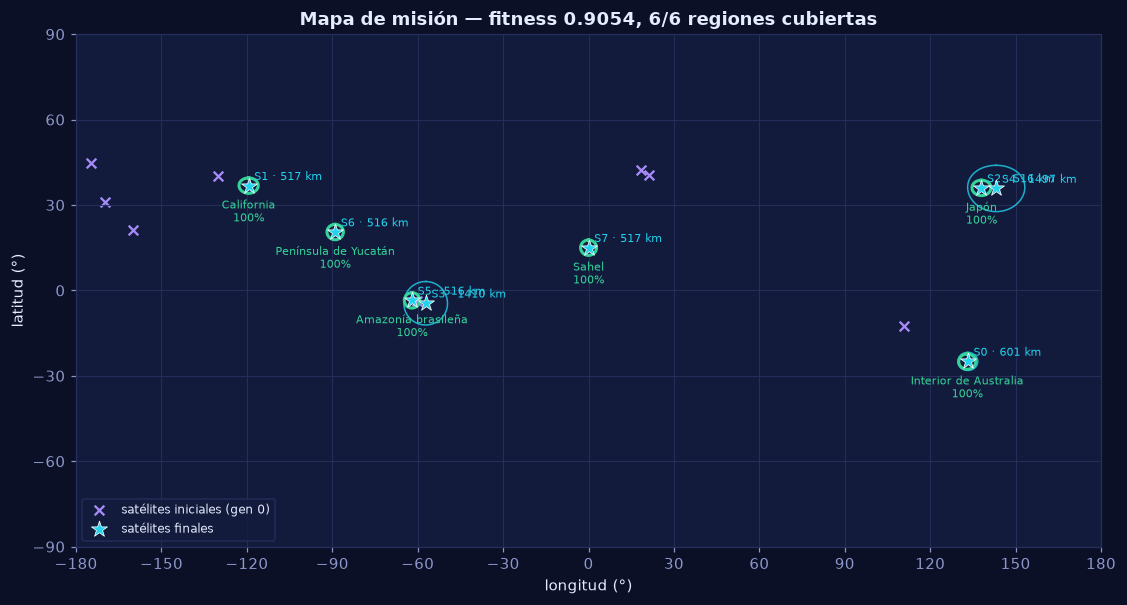

In [15]:
r1 = X.e1_initial(CFG, seed=0)
print(X.summarize(r1))
display(r1.best_eval.region_table())
display(acceptance(r1.best_eval, r1.scenario))
plot_mission_map(r1.scenario, r1.best, r1.initial_best); plt.show()

**Interpretación (ejecución de referencia):** el AG pasa de fitness 0.270 (el mejor individuo aleatorio)
a **0.9054** y cubre las 6/6 regiones desde la generación 11.
En el mapa, las ✕ moradas son la mejor configuración aleatoria inicial y las ★ cian, la final.

## 3. Etapa 2 — con zonas de desechos y posiciones ocupadas (pruebas E2: evolución)

In [16]:
base = X.e2_base(CFG, seed=0)
print(X.summarize(base))
display(base.best_eval.region_table())
display(base.best_eval.satellite_table(base.scenario))
display(acceptance(base.best_eval, base.scenario))

{'scenario': 'base', 'seed': 0, 'fitness': 0.9174, 'initial_fitness': 0.2103, 'feasible': True, 'violation_deg': 0.0, 'regions_covered': 6, 'weighted_coverage': 1.0, 'accepted': True, 'convergence_gen': 314, 'full_coverage_gen': 14, 'generations': 400, 'evaluations': 48122, 'time_s': 3.97, 'bound': 0.9179}


,región,prioridad,peso,cobertura,redundancia,resolución,score,cubierta,satélites
0,Península de Yucatán,alta,3.0,1.0,1.0,0.990,0.999,sí,"3,5"
1,Amazonía brasileña,alta,3.0,1.0,1.0,0.990,0.998,sí,"1,6"
2,California,media,2.0,1.0,0.0,0.989,0.848,sí,0
3,Sahel,media,2.0,1.0,0.0,0.987,0.848,sí,4
4,Japón,media,2.0,1.0,0.0,0.989,0.848,sí,7
5,Interior de Australia,normal,1.0,1.0,0.0,0.968,0.845,sí,2


,sat,lat,lon,alt_km,huella_km
0,0,36.81,-119.39,516.0,302.0
1,1,0.11,-63.84,1537.0,930.0
2,2,-25.05,132.87,548.0,321.0
3,3,20.50,-89.00,515.0,301.0
4,4,15.01,0.01,519.0,304.0
5,5,18.46,-87.16,1445.0,871.0
6,6,-3.49,-61.99,516.0,302.0
7,7,36.01,138.02,516.0,302.0


{'C1 válida (sin violaciones)': True,
 'C2 todas las regiones cubiertas': True,
 'C3 ≥2 regiones Alta con redundancia ≥ 95%': True,
 'C4 fitness ≥ 90% de la cota de referencia': True,
 'ACEPTADA': True}

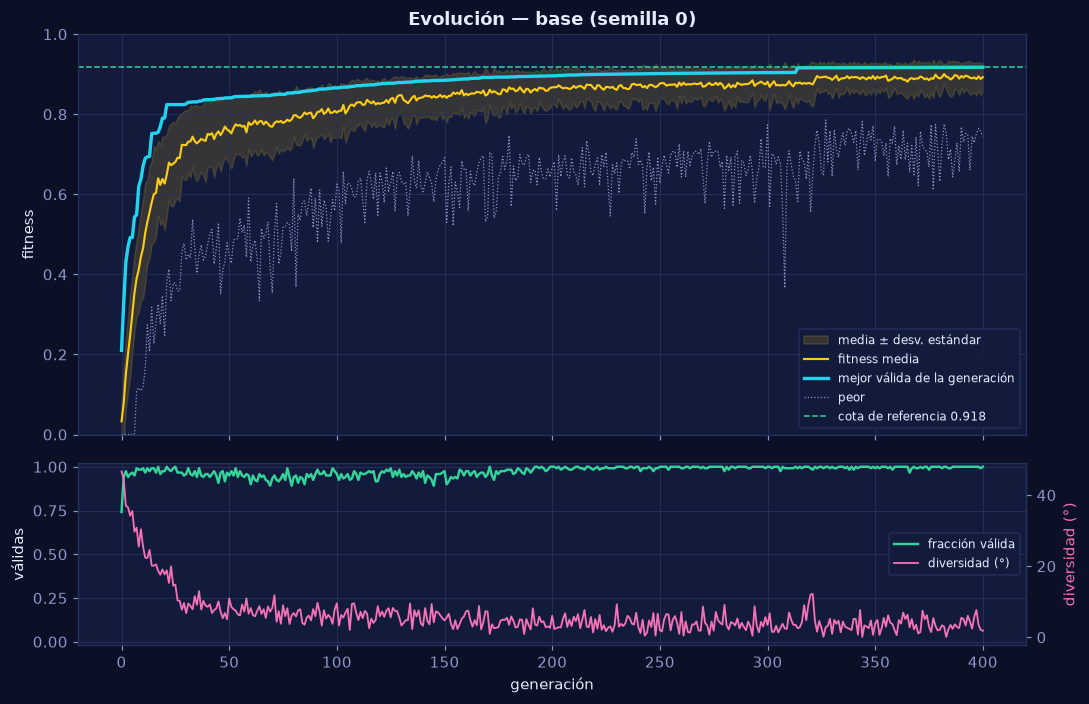

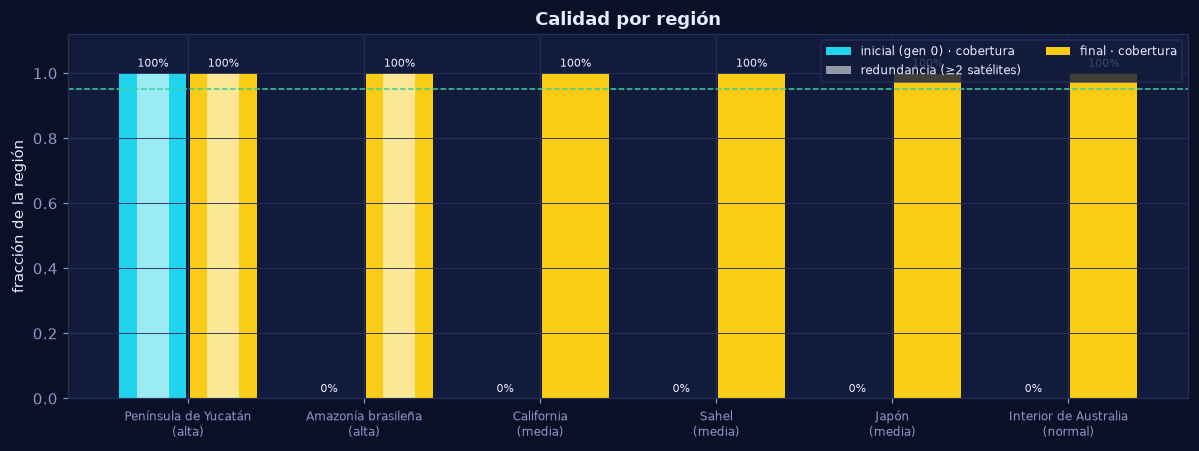

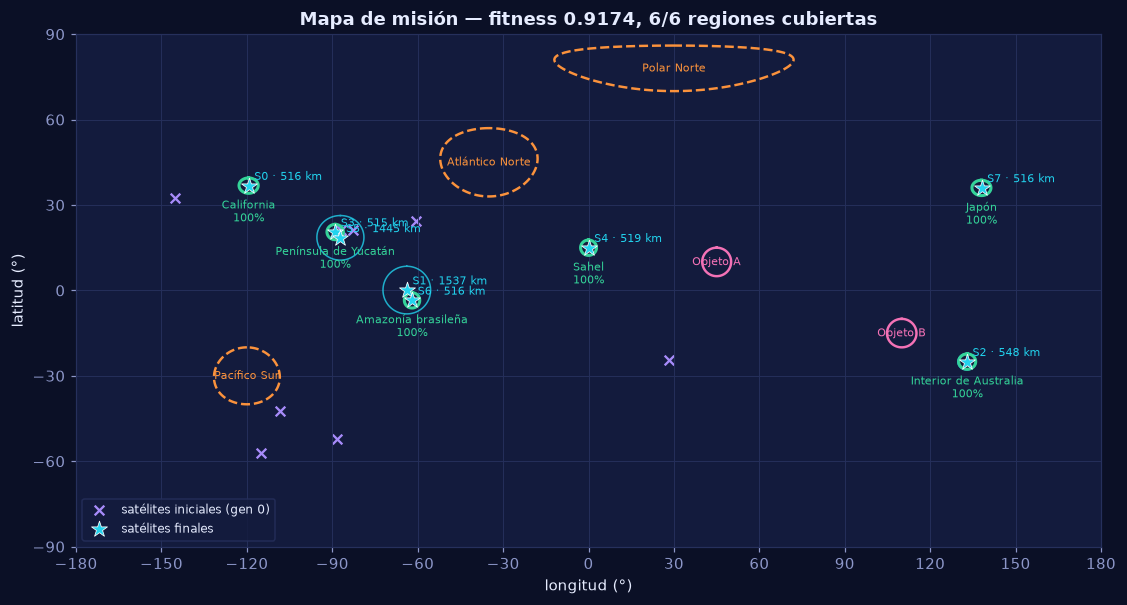

,generation,best_fitness,mean_fitness,std_fitness,feasible_ratio,diversity_deg,sigma_deg
0,0,0.2103,0.0329,0.0593,0.7417,46.6418,12.0000
10,10,0.6707,0.4653,0.1251,0.9917,25.5129,10.6046
25,25,0.8240,0.6807,0.0954,1.0000,14.7896,8.6300
50,50,0.8409,0.7584,0.0837,0.9500,10.9195,6.1217
100,100,0.8657,0.8041,0.0629,0.9583,9.5224,3.0804
200,200,0.8958,0.8669,0.0403,1.0000,6.0313,0.7799
300,300,0.9039,0.8812,0.0305,1.0000,3.4228,0.1975
400,400,0.9174,0.8927,0.0346,1.0000,1.8244,0.0500


In [17]:
plot_evolution(base); plt.show()
plot_regions({"inicial (gen 0)": base.initial_eval, "final": base.best_eval}); plt.show()
plot_mission_map(base.scenario, base.best, base.initial_best); plt.show()
h = base.history_frame()
display(h.iloc[[0, 10, 25, 50, 100, 200, 300, len(h) - 1]][
    ["generation", "best_fitness", "mean_fitness", "std_fitness", "feasible_ratio", "diversity_deg", "sigma_deg"]].round(4))

**Interpretación (ejecución de referencia):**

* **Mejora:** el fitness pasa de 0.2103 a **0.9174**, que es el
  99.94 % de la cota de referencia (0.9179).
  Las 6 regiones quedan cubiertas desde la generación 14 y se alcanza el 99 % del valor final en la
  generación 314.
* **Dos fases visibles:** primero *exploración*, con σ de mutación alto, diversidad alta y saltos grandes en las primeras
  ~30 generaciones (la diversidad baja de ~47° a ~7°); después *explotación*, con σ decayendo exponencialmente de 12° a
  0.05°, la diversidad bajando a ~2° y ajustes finos de altitud hasta ≈ 515 km, que son los que suben la resolución.
* **Estrategia emergente:** cada región tiene su satélite casi exacto sobre el centro a ≈ 515 km (el mínimo que cubre los
  300 km). Los 2 satélites sobrantes se usaron como **redundancia en las dos regiones Alta**, a mayor altitud (~1400–1500 km)
  y desplazados ≥ 2° para respetar la separación mínima. Nadie programó esa regla: **surge de la función de evaluación.**
* **Restricciones:** el 74 % de la población aleatoria inicial era válida. Las
  inválidas desaparecen por las reglas de Deb, y la solución final no tiene ninguna violación.

## 4. Visualización 3D de la constelación (Entregable 5)

Globo **WebGL interactivo** (globe.gl) generado con los datos **reales** de la ejecución anterior:

* 🟢/🔴 regiones cubiertas o no cubiertas, con anillos pulsantes · 🟠 zonas de desechos · 🩷 posiciones ocupadas
* columnas cian = satélites a su **altitud real a escala** · círculos cian = huellas del sensor
* pestañas **Inicial (gen 0) / Generación 50 / Final** para comparar la evolución, y la opción *Superponer otro estado*
* arrastra para girar, rueda para acercar, pasa el cursor sobre cualquier objeto para ver sus datos

También se guarda como `outputs/globe.html`, que se abre en cualquier navegador.

In [18]:
_ = show_globe(base.scenario, {"Inicial (gen 0)": base.initial_best, "Generación 50": base.snapshots[50], "Final": base.best},
               height=680, save_to="outputs/globe.html")

Vista alternativa (Plotly, proyección ortográfica girable) para comparar lado a lado la configuración inicial y la final:

In [19]:
plotly_comparison(base.scenario, base.initial_best, base.best).show()

## 5. Pruebas y validación (Entregable 3)

Cada prueba registra **condiciones → resultados → interpretación**. Los valores de las interpretaciones vienen de la
ejecución de referencia (`outputs/results.json`). Si tu ejecución difiere ligeramente por la versión de numpy, la
conclusión debe ser la misma.

### 5.1 Variación entre ejecuciones (E7) y comparación con métodos de referencia

**Condiciones:** escenario base, 10 semillas distintas, los mismos parámetros y el mismo presupuesto de
48,122 evaluaciones para el AG y para la búsqueda aleatoria. La heurística voraz agrega satélites
uno por uno, siempre el de mayor ganancia.

,seed,fitness,initial_fitness,regions_covered,accepted,full_coverage_gen,convergence_gen,time_s
0,0,0.9174,0.2103,6,True,14,314,3.93
1,1,0.9175,0.2188,6,True,15,197,3.97
2,2,0.9176,0.1645,6,True,41,210,3.95
3,3,0.9176,0.1939,6,True,17,193,3.93
4,4,0.9060,0.2096,6,False,23,196,3.94
5,5,0.9046,0.2099,6,False,16,205,3.96
6,6,0.9176,0.1678,6,True,20,318,3.96
7,7,0.9176,0.1745,6,True,16,197,4.03
8,8,0.9175,0.1990,6,True,15,224,3.77
9,9,0.9176,0.2023,6,True,32,219,3.87


,valor
n_runs,10.000000
budget_evaluations,48122.000000
ga_mean,0.915100
ga_std,0.005176
ga_min,0.904600
ga_max,0.917600
ga_cv_percent,0.565623
ga_accepted,8.000000
random_mean,0.423195
random_max,0.456722


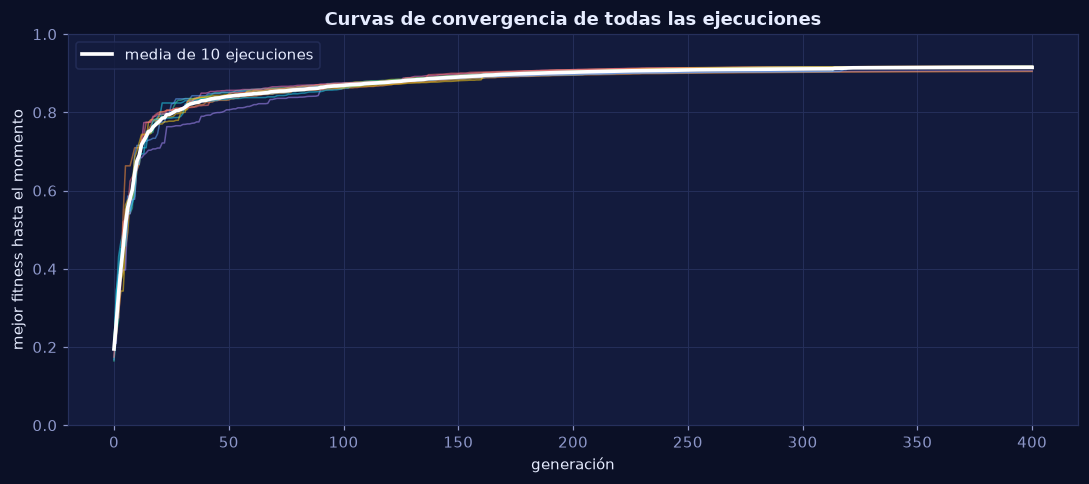

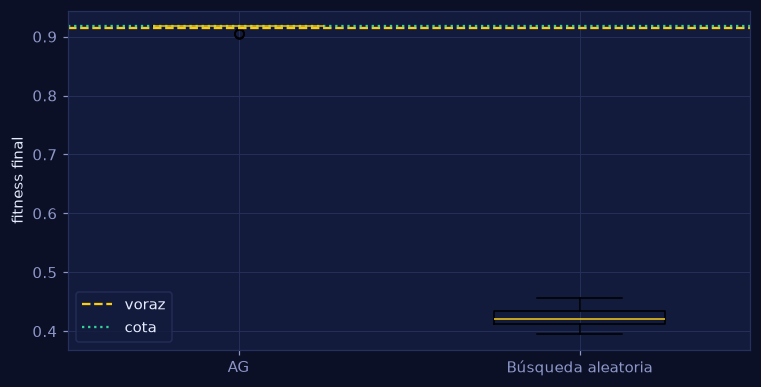

Distancia media (°) entre las soluciones de cada par de semillas:


,s0,s1,s2,s3,s4,s5,s6,s7,s8,s9
0,0.0,1.5,1.2,1.8,11.3,17.3,0.8,0.6,0.7,1.1
1,1.5,0.0,1.1,1.0,11.4,17.7,1.1,0.9,1.5,1.2
2,1.2,1.1,0.0,0.8,12.1,17.6,1.4,1.3,1.4,0.2
3,1.8,1.0,0.8,0.0,12.1,17.2,1.5,1.4,2.0,1.0
4,11.3,11.4,12.1,12.1,0.0,18.4,11.0,11.0,10.9,12.0
5,17.3,17.7,17.6,17.2,18.4,0.0,17.2,17.2,17.7,17.4
6,0.8,1.1,1.4,1.5,11.0,17.2,0.0,0.3,1.3,1.3
7,0.6,0.9,1.3,1.4,11.0,17.2,0.3,0.0,1.1,1.1
8,0.7,1.5,1.4,2.0,10.9,17.7,1.3,1.1,0.0,1.3
9,1.1,1.2,0.2,1.0,12.0,17.4,1.3,1.1,1.3,0.0


In [20]:
runs, table, summary, rnd, dist = X.e7_variation(CFG, seeds=range(N_SEEDS))
display(table[["seed", "fitness", "initial_fitness", "regions_covered", "accepted", "full_coverage_gen", "convergence_gen", "time_s"]])
display(pd.Series(summary).to_frame("valor"))
plot_runs(runs); plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([table["fitness"], rnd], widths=0.5); ax.set_xticks([1, 2], ["AG", "Búsqueda aleatoria"])
ax.axhline(summary["greedy"], color="#FACC15", ls="--", label="voraz"); ax.axhline(summary["bound"], color="#34D399", ls=":", label="cota")
ax.set_ylabel("fitness final"); ax.legend(); plt.show()
print("Distancia media (°) entre las soluciones de cada par de semillas:")
display(pd.DataFrame(dist, columns=[f"s{i}" for i in range(len(dist))]).round(1))

**Interpretación:**

* **Estabilidad:** fitness 0.9151 ± 0.0052 (CV = 0.57 %), rango
  [0.9046, 0.9176]. Las 10 ejecuciones cubren 6/6 regiones y son válidas; 8/10
  cumplen **todos** los criterios de aceptación. Las 2 que fallan (semillas 4 y 5, fitness ≈ 0.905) lo hacen **solo por C3**:
  uno de los satélites de redundancia quedó sobre una región Media (Sahel o Japón) en lugar de la segunda Alta. Es un
  **óptimo local**: para salir de ahí habría que mover un satélite ~90° de golpe, y la mutación fina ya no da saltos tan
  grandes.
* **AG vs. aleatoria:** con el mismo presupuesto, la búsqueda aleatoria se queda en 0.423 (máx.
  0.457). La prueba de Mann-Whitney unilateral da p = 8.1e-05: la diferencia
  es estadísticamente significativa. **El AG no está ganando por suerte.**
* **AG vs. voraz:** la heurística voraz (0.9142) usa conocimiento del dominio, porque solo prueba posiciones
  cercanas a los centros de las regiones. El AG parte de cero, la iguala en promedio y la supera en su mejor ejecución
  (0.9176). El AG **no conoce** dónde están las regiones; lo descubre.
* **Soluciones distintas con calidad similar:** la distancia media entre soluciones es 6.2°
  (máx. 18.4°). El paisaje es **multimodal**: los satélites base casi coinciden, pero los
  dos de redundancia cambian de posición según la semilla. Por eso se reportan distribuciones y no una sola corrida.

### 5.2 Zonas restringidas por desechos (E3) y posiciones ocupadas (E4)

**Condiciones:** auditoría geométrica independiente del AG: para la mejor solución de **cada** semilla se mide la distancia del satélite más cercano a cada zona.

In [21]:
audit = X.e3_e4_constraint_audit(runs)
display(audit.groupby(["zona", "tipo", "radio_deg"]).agg(distancia_mín=("distancia_deg", "min"),
        margen_mín=("margen_deg", "min"), todas_respetan=("respeta", "all")).reset_index())
print("Fracción válida en la población aleatoria inicial:", np.mean([r.history[0]["feasible_ratio"] for r in runs]).round(3))
print("Fracción válida en la población final:          ", np.mean([r.history[-1]["feasible_ratio"] for r in runs]).round(3))

,zona,tipo,radio_deg,distancia_mín,margen_mín,todas_respetan
0,Atlántico Norte,debris,12.0,42.03,30.03,True
1,Objeto A,occupied,5.0,41.38,36.38,True
2,Objeto B,occupied,5.0,23.49,18.49,True
3,Pacífico Sur,debris,10.0,55.56,45.56,True
4,Polar Norte,debris,8.0,58.46,50.46,True


Fracción válida en la población aleatoria inicial: 0.785
Fracción válida en la población final:           0.998


**Prueba de estrés E4:** el *Objeto A* se reubica a solo 2° del centro del Sahel, de modo que su zona de exclusión invade la región.

,zona,tipo,radio_deg,sat_más_cercano,distancia_deg,margen_deg,respeta
0,Atlántico Norte,debris,12.0,1,40.23,28.23,True
1,Pacífico Sur,debris,10.0,3,58.65,48.65,True
2,Polar Norte,debris,8.0,5,58.48,50.48,True
3,Objeto B,occupied,5.0,7,23.77,18.77,True
4,Objeto A (reubicado),occupied,5.0,1,5.00,0.00,True


,región,prioridad,peso,cobertura,redundancia,resolución,score,cubierta,satélites
0,Península de Yucatán,alta,3.0,1.0,1.0,0.990,0.998,sí,"2,3"
1,Amazonía brasileña,alta,3.0,1.0,1.0,0.990,0.999,sí,"4,6"
2,California,media,2.0,1.0,0.0,0.990,0.849,sí,0
3,Sahel,media,2.0,1.0,0.0,0.615,0.792,sí,1
4,Japón,media,2.0,1.0,0.0,0.989,0.848,sí,5
5,Interior de Australia,normal,1.0,1.0,0.0,0.987,0.848,sí,7


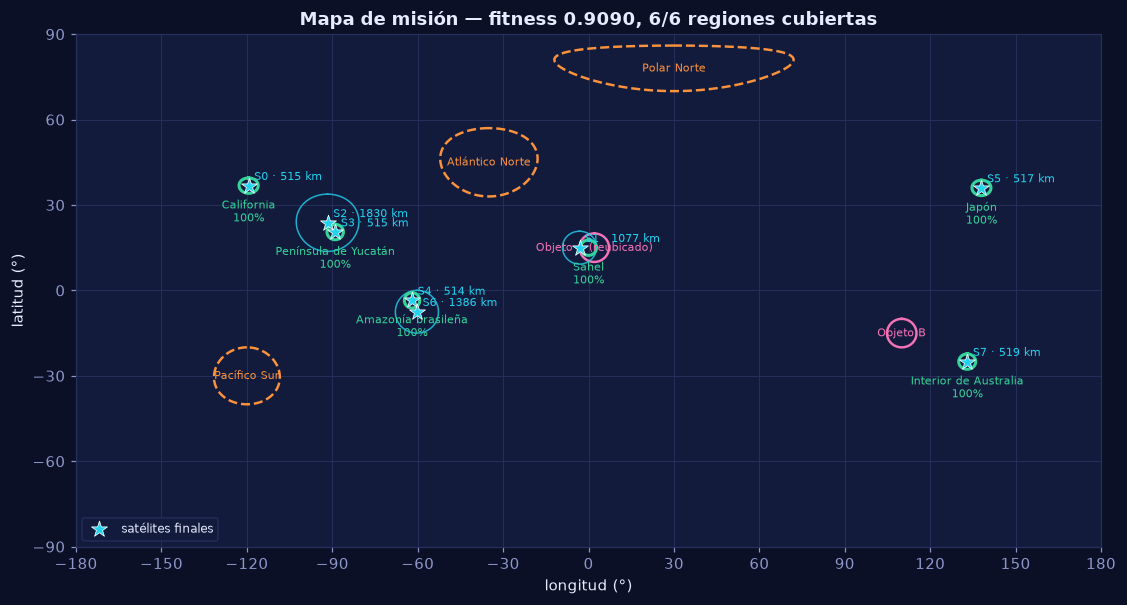

In [22]:
near = X.e4_object_near_region(CFG, seed=0)
display(X.zone_margins(near.best, near.scenario))
display(near.best_eval.region_table())
plot_mission_map(near.scenario, near.best); plt.show()

**Interpretación:**

* **Las 5 zonas se respetan en las 10 ejecuciones** (`todas_respetan = True`).
  Margen mínimo por zona: Atlántico Norte 30.0°, Objeto A 36.4°, Objeto B 18.5°, Pacífico Sur 45.6°, Polar Norte 50.5°.
* La población inicial tenía 21 % de configuraciones inválidas; al final
  queda 100 % de válidas. Las inválidas restantes son hijos recién mutados que
  la selección descarta.
* **Observación honesta:** en el escenario base, las zonas quedan lejos de las regiones, así que *en el óptimo* las
  restricciones no están activas. Por eso las pruebas E4-estrés, E5 y E6 las ponen **encima** de las regiones.
* **E4 estrés:** el satélite del Sahel se coloca **exactamente en el borde** de la zona de exclusión (margen
  0.00°) y sube de ~519 km a ~1077 km para
  alcanzar la región desde fuera: cobertura 100%, pero la resolución baja a 0.61. La restricción tiene
  **un costo medible**: el fitness baja de 0.9174 a 0.9090.

### 5.3 Espacio reducido (E5)

**Condiciones:** se reduce el espacio en 4 niveles acumulativos: R0 base → R1 + zona de 6° centrada a 2.6° de Yucatán → R2 + techo de altitud de 1200 km → R3 + zona sobre Japón. Además, R1 se corre **sin manejo de restricciones** (`constraint_handling='none'`) para ver qué está evitando el sistema.

,scenario,fitness,feasible,regions_covered,accepted,bound,full_coverage_gen
0,R0 base,0.9174,True,6,True,0.9179,14
1,R1 +zona sobre Yucatán,0.8920,True,6,False,0.9179,8
2,R2 R1 + techo 1200 km,0.8742,True,6,False,0.9164,99
3,R3 R2 + zona sobre Japón,0.8697,True,6,False,0.9164,118


R0 base → altitudes: [516, 1537, 548, 515, 519, 1445, 516, 516]
R1 +zona sobre Yucatán → altitudes: [519, 516, 1125, 518, 515, 517, 1799, 1361]
R2 R1 + techo 1200 km → altitudes: [517, 1127, 515, 515, 1126, 514, 517, 1159]
R3 R2 + zona sobre Japón → altitudes: [515, 1127, 518, 516, 646, 1043, 517, 1168]

R1 SIN manejo de restricciones: 0.9174 | válida: False
   ✗ S0 viola Desechos Golfo de México: 2.66° < 6.0°
   ✗ S4 viola Desechos Golfo de México: 2.54° < 6.0°
   ✗ S0 viola sat 4: 0.14° < 2.0°
   ✗ S2 viola sat 6: 1.09° < 2.0°


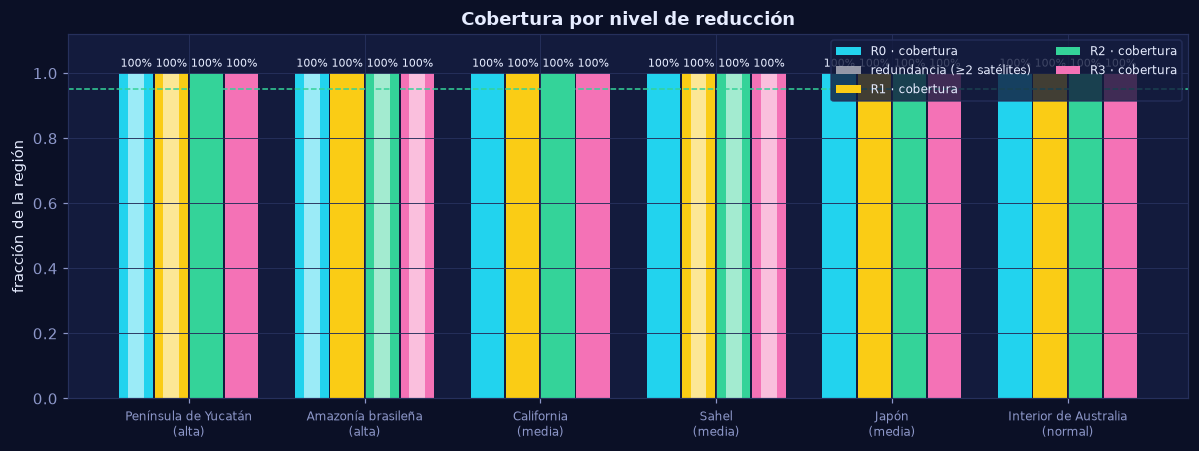

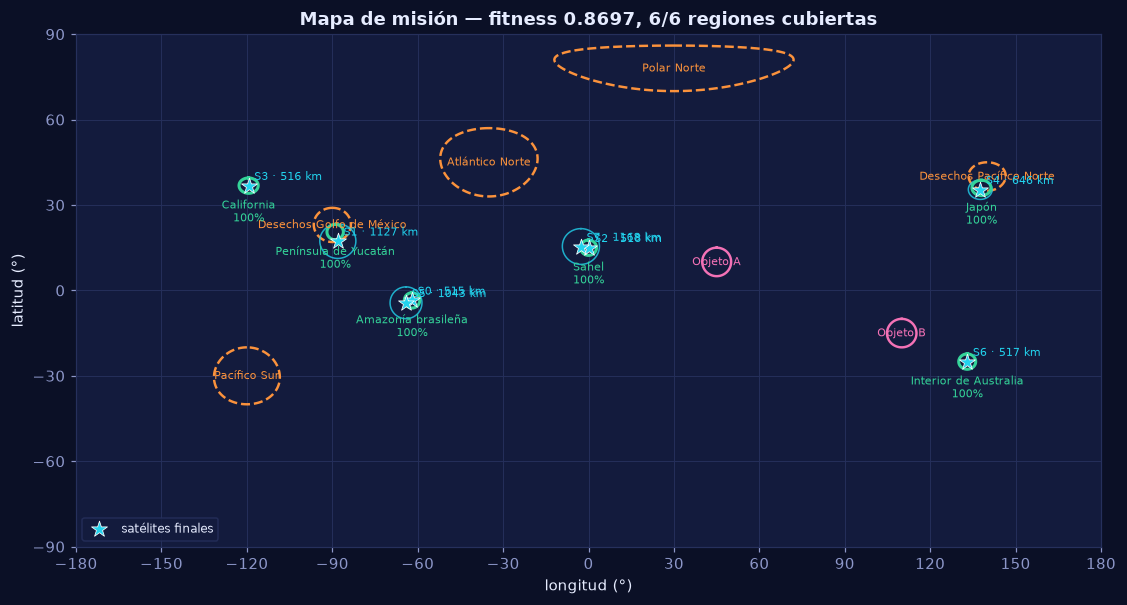

In [23]:
red, unc = X.e5_reduced_space(CFG, seed=0)
display(pd.DataFrame([X.summarize(r) for r in red])[["scenario", "fitness", "feasible", "regions_covered", "accepted", "bound", "full_coverage_gen"]])
for r in red:
    print(r.scenario.name, "→ altitudes:", r.best[:, 2].round(0).astype(int).tolist())
print("\nR1 SIN manejo de restricciones:", X.summarize(unc)["fitness"], "| válida:", unc.best_eval.feasible)
for v in unc.best_eval.violations:
    print(f"   ✗ S{v.satellite} viola {v.target}: {v.distance_deg:.2f}° < {v.limit_deg}°")
plot_regions({r.scenario.name.split(" ")[0]: r.best_eval for r in red}, "Cobertura por nivel de reducción"); plt.show()
plot_mission_map(red[3].scenario, red[3].best); plt.show()

**Interpretación:**

* El fitness baja de forma monótona conforme se reduce el espacio: 0.9174 → 0.8920 → 0.8742 → 0.8697.
  **Las 6 regiones siguen cubiertas en todos los niveles**: el AG compensa subiendo satélites o alejándolos de las zonas,
  y lo que se pierde es resolución y redundancia.
* **Sin manejo de restricciones**, el AG pone satélites *dentro* de la zona del Golfo (fitness aparente
  0.9174, pero con 9.6° de intrusión total).
  Es una configuración con mejor puntaje que **no es válida**, justo lo que advierte el enunciado. Con las reglas de Deb, la
  solución de R1 (0.8920) es peor en puntaje pero **válida**.
* El techo de 1200 km (R2) impide la estrategia de "huella grande", así que la redundancia se vuelve más cara.

### 5.4 Condiciones difíciles o inviables (E6)

Tres tipos de dificultad, de distinta naturaleza:

| Caso | Qué lo hace difícil |
|---|---|
| I1 | Zona de 15° centrada en la Amazonía: ninguna huella (máx. 11°) puede alcanzarla desde fuera → **objetivo inalcanzable** |
| I2 | Solo 5 satélites para 6 regiones → **recursos insuficientes** |
| I3 | Separación mínima de 80° entre 8 satélites: imposible por geometría (problema de Tammes, máx. ≈ 74.9°) → **ninguna configuración válida existe** |

,scenario,fitness,feasible,violation_deg,regions_covered,accepted
0,I1 Amazonía inalcanzable,0.7334,True,0.000,5,False
1,I2 solo 5 satélites,0.7668,True,0.000,5,False
2,I3 separación 80° imposible,0.0000,False,65.008,0,False


I1 Amazonía inalcanzable: regiones sin cubrir = ['Amazonía brasileña'] | violaciones = 0
I2 solo 5 satélites: regiones sin cubrir = ['Interior de Australia'] | violaciones = 0
I3 separación 80° imposible: regiones sin cubrir = ['Península de Yucatán', 'Amazonía brasileña', 'California', 'Sahel', 'Japón', 'Interior de Australia'] | violaciones = 13


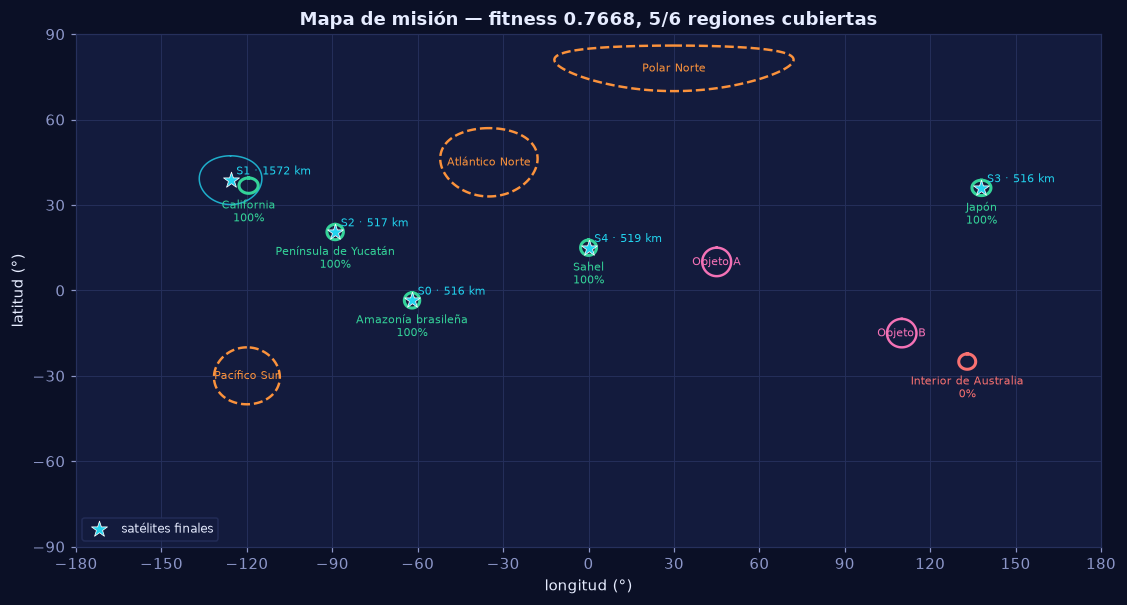

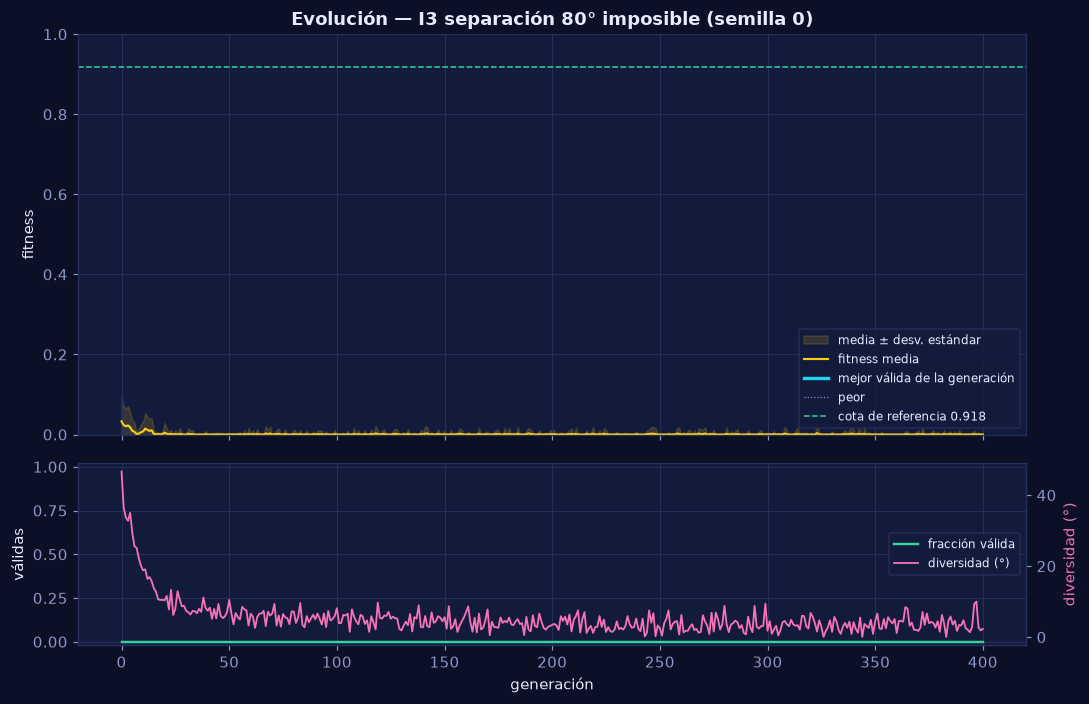

In [24]:
inf = X.e6_infeasible(CFG, seed=0)
display(pd.DataFrame([X.summarize(r) for r in inf.values()])[["scenario", "fitness", "feasible", "violation_deg", "regions_covered", "accepted"]])
for k, r in inf.items():
    lost = [x.name for x in r.best_eval.regions if not x.covered]
    print(f"{k}: regiones sin cubrir = {lost} | violaciones = {len(r.best_eval.violations)}")
plot_mission_map(inf["I2 solo 5 satélites"].scenario, inf["I2 solo 5 satélites"].best); plt.show()
plot_evolution(inf["I3 separación 80° imposible"]); plt.show()

**Interpretación:**

* **I1:** el sistema **no hace trampa**. Entrega una solución válida (fitness 0.7334)
  con la Amazonía al 0 % y las otras 5 regiones cubiertas, y lo reporta explícitamente (criterio C2 = falso).
* **I2:** con 5 satélites, el AG **sacrifica el Interior de Australia**, la única región de prioridad Normal. Las
  prioridades sí deciden qué se pierde cuando no alcanza para todo.
* **I3:** no existe ninguna configuración válida. El AG lo reporta (`feasible = False`, curva de mejor válida vacía) y
  devuelve la configuración que **menos** viola: 13 pares de satélites,
  65.0° de intrusión total. La gráfica muestra la fracción válida en 0
  durante toda la ejecución. **Que el algoritmo termine no significa que haya resuelto el problema.**

### 5.5 Cambio en las condiciones (E9, sección 3.3 del enunciado)

**Condiciones:** (a) el Interior de Australia sube a prioridad Alta; (b) aparece una zona de desechos de 3° justo donde está el satélite que observa Japón. Primero se **revalida** la solución anterior y luego se re-optimiza partiendo de la población previa (*warm start*) y, para comparar, desde cero.

,(a) prioridad,(b) zona nueva
válida_antes,True,True
válida_ahora,True,False
fitness_antes,0.9174,0.9174
fitness_ahora,0.9078,0.9174
regiones_cubiertas_ahora,6,6
violaciones,[],[sat 7 en Desechos nuevos (0.00° < 3.0°)]
aceptada_ahora,True,False


,modo,fitness,initial_fitness,feasible,accepted,convergence_gen,bound
0,(a) warm,0.9086,0.9078,True,True,0,0.9087
1,(b) warm,0.9092,0.7868,True,True,26,0.9179
2,(b) desde cero,0.8820,0.2103,True,False,96,0.9179


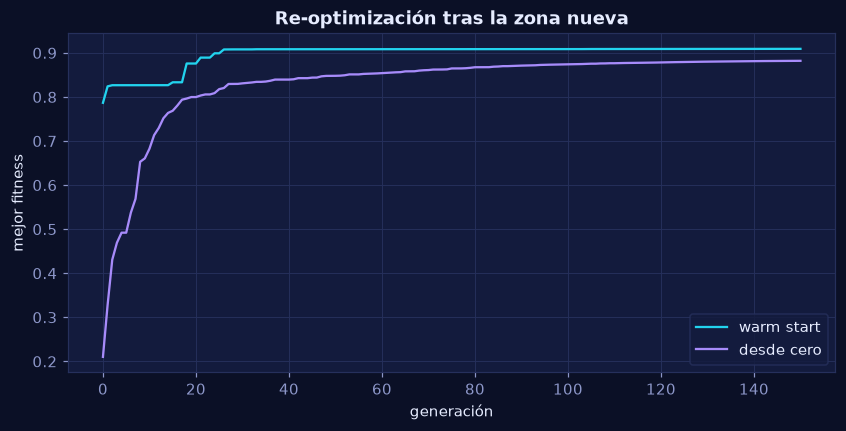

In [25]:
ch = X.e9_change_of_conditions(base, CFG, seed=0)
display(pd.DataFrame({"(a) prioridad": ch["prioridad"]["revalidación"], "(b) zona nueva": ch["zona_nueva"]["revalidación"]}))
display(pd.DataFrame([X.summarize(ch["prioridad"]["reoptimizado"]) | {"modo": "(a) warm"},
                      X.summarize(ch["zona_nueva"]["warm"]) | {"modo": "(b) warm"},
                      X.summarize(ch["zona_nueva"]["cold"]) | {"modo": "(b) desde cero"}])
        [["modo", "fitness", "initial_fitness", "feasible", "accepted", "convergence_gen", "bound"]])
fig, ax = plt.subplots(figsize=(9, 4))
for k, c, lab in (("warm", "#22D3EE", "warm start"), ("cold", "#A78BFA", "desde cero")):
    ax.plot([max(h["best_so_far_rank"], -0.05) for h in ch["zona_nueva"][k].history], color=c, label=lab)
ax.set_xlabel("generación"); ax.set_ylabel("mejor fitness"); ax.legend(); ax.set_title("Re-optimización tras la zona nueva"); plt.show()

**Interpretación:**

* **(a) Prioridad:** la solución anterior **sigue siendo válida**, porque una prioridad no cambia la geometría, pero su
  fitness cambia de 0.9174 a 0.9078
  porque cambian los pesos. La re-optimización llega a 0.9086, frente a una cota de
  0.9087.
* **(b) Zona nueva:** la solución anterior **deja de ser válida** (sat 7 en Desechos nuevos (0.00° < 3.0°)),
  aunque su fitness no haya cambiado. Esto demuestra que el puntaje y la validez son cosas distintas.
  Con *warm start*, el AG la repara y llega a 0.9092 en
  26 generaciones. Desde cero, con el mismo presupuesto, solo alcanza
  0.8820. **Reutilizar la población anterior es más eficiente que empezar de nuevo.**

### 5.6 Prueba propia: robustez ante la falla de un satélite (E8)

**Pregunta:** ¿el término de redundancia del fitness tiene valor real o solo infla el puntaje? **Condiciones:** para la solución base se simula la falla de cada satélite (análisis N-1) y se compara contra una solución optimizada **sin** término de redundancia (pesos 0.80 / 0 / 0.20).

In [26]:
rob = X.e8_robustness(base, CFG, seed=0)
print("CON término de redundancia"); display(rob["con_redundancia"])
print("SIN término de redundancia"); display(rob["sin_redundancia"])

CON término de redundancia


,satélite_fallado,fitness,cobertura_ponderada,regiones_cubiertas,regiones_perdidas
0,0,0.7869,0.8462,5,California
1,1,0.8828,1.0000,6,ninguna
2,2,0.8524,0.9231,5,Interior de Australia
3,3,0.8613,1.0000,6,ninguna
4,4,0.7869,0.8462,5,Sahel
5,5,0.8828,1.0000,6,ninguna
6,6,0.8592,1.0000,6,ninguna
7,7,0.7869,0.8462,5,Japón


SIN término de redundancia


,satélite_fallado,fitness,cobertura_ponderada,regiones_cubiertas,regiones_perdidas
0,0,0.7179,0.8462,5,California
1,1,0.7831,0.9231,5,Interior de Australia
2,2,0.8484,1.0000,6,ninguna
3,3,0.8484,1.0000,6,ninguna
4,4,0.6526,0.7692,5,Península de Yucatán
5,5,0.7179,0.8462,5,Sahel
6,6,0.7179,0.8462,5,Japón
7,7,0.6526,0.7692,5,Amazonía brasileña


**Interpretación:** con el término de redundancia, **4 de 8** fallas posibles no
hacen perder ninguna región, y el fitness medio tras una falla es 0.8374. Sin él,
solo 2 de 8 fallas son inocuas (0.7423),
y una falla puede dejar **sin cobertura una región Alta**. El término de redundancia hace que la constelación sea más
**tolerante a fallas** precisamente donde más importa.

### 5.7 Correspondencia entre los datos y la visualización

El globo y los mapas se construyen con `Evaluator.evaluate()` sobre las mismas configuraciones que devuelve el AG. Esta celda lo verifica: lee los datos embebidos en `outputs/globe.html` y los compara con el resultado.

In [27]:
import json, re
html = open("outputs/globe.html", encoding="utf-8").read()
data = json.loads(re.search(r"const D = (\{.*?\});\n", html, re.S).group(1))
final = data["states"][-1]
cfg_globe = np.array([[s["lat"], s["lng"], s["alt_km"]] for s in final["satellites"]])
assert np.allclose(cfg_globe, base.best), "¡el globo no muestra la constelación del AG!"
assert abs(final["fitness"] - base.best_eval.fitness) < 1e-12
assert [r["covered"] for r in final["regions"]] == [r.covered for r in base.best_eval.regions]
print("✔ El globo muestra exactamente la configuración, el fitness y la cobertura que calculó el AG.")

✔ El globo muestra exactamente la configuración, el fitness y la cobertura que calculó el AG.


### 5.8 Calibración y ablación de operadores (E10)

**Condiciones:** escenario R1 (las restricciones sí afectan aquí), 5 semillas por variante. Se apaga un operador a la vez para medir su aporte.

,variante,fitness_media,fitness_std,válidas,conv_gen_media
0,configuración final,0.8963,0.0059,5,197.2
1,sin alineación en cruce,0.8953,0.0052,5,188.4
2,sin reparación,0.8939,0.0054,5,216.8
3,sin elitismo,0.8969,0.0056,5,259.8
4,mutación alta (0.5),0.8892,0.0072,5,303.6
5,penalización en vez de Deb,0.8964,0.0065,5,200.6
6,población 40,0.8894,0.0014,5,226.2


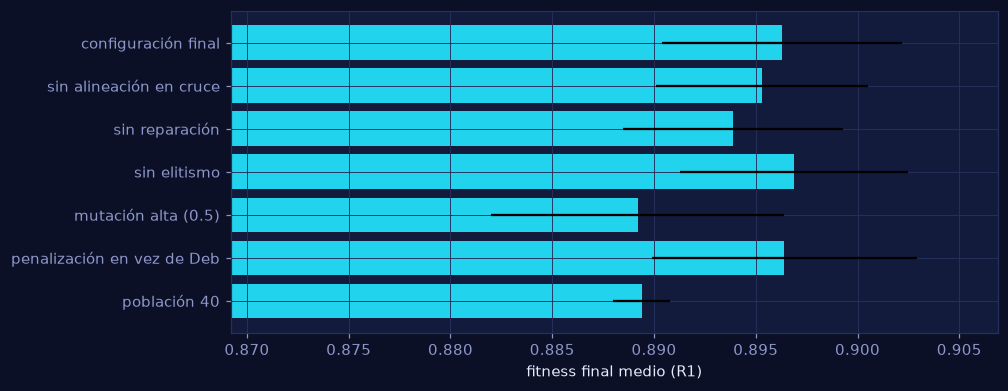

In [28]:
abl_runs, abl = X.e10_ablation(CFG, seeds=range(5))
display(abl)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(abl["variante"], abl["fitness_media"], xerr=abl["fitness_std"], color="#22D3EE")
ax.set_xlim(abl["fitness_media"].min() - 0.02, abl["fitness_media"].max() + 0.01); ax.invert_yaxis()
ax.set_xlabel("fitness final medio (R1)"); plt.show()

**Interpretación:** consulta `docs/04_analisis_resultados.md` para la discusión completa. En resumen, la mutación alta y
la población pequeña empeoran claramente el resultado. Varias diferencias entre variantes son del mismo orden que la
desviación estándar, **así que no son concluyentes con 5 semillas**, y lo reportamos así en lugar de sobreinterpretarlas.
La calibración inicial (registrada en el análisis) mostró que **el número de generaciones y el ajuste fino final**
(σ final de 0.05° y 2 km) son los parámetros que más mejoran el resultado: con 250 generaciones el fitness medio era
0.894, con 400 subió a 0.908 y con la combinación final (más el elitismo 4, el torneo 4 y la mutación 0.15) llegó a 0.9175.

## 6. Pruebas unitarias automatizadas

Pruebas con `pytest`: geometría, cobertura, cada zona prohibida, separación, reproducibilidad, caso inviable, *warm start*, AG frente a la búsqueda aleatoria y operadores.

In [29]:
import sys
!{sys.executable} -m pytest -q

.....

.

.

.

.

........................

..                                      [100%]
35 passed in 2.29s


## 7. Laboratorio interactivo

Modifica las condiciones y observa el efecto. En Colab aparecen controles de formulario a la derecha de la celda.

In [30]:
#@title Escenario personalizado { run: "manual" }
prioridad_australia = "normal"  #@param ["alta", "media", "normal"]
techo_altitud_km = 2000  #@param {type:"slider", min:600, max:2000, step:100}
nueva_zona_lat = 36.0  #@param {type:"number"}
nueva_zona_lon = 138.0  #@param {type:"number"}
nueva_zona_radio = 0.0  #@param {type:"slider", min:0, max:20, step:0.5}
generaciones = 200  #@param {type:"slider", min:20, max:600, step:20}
semilla = 42  #@param {type:"integer"}

lab = default_scenario().with_priority("Interior de Australia", prioridad_australia).with_params(alt_max_km=float(techo_altitud_km))
if nueva_zona_radio > 0:
    lab = lab.with_zone(Zone("Zona del laboratorio", nueva_zona_lat, nueva_zona_lon, nueva_zona_radio))
print("Solución base revalidada en el nuevo escenario:", X.revalidate(base.best, base.scenario, lab))
rl = run_ga(lab, GAConfig(generations=generaciones), seed=semilla)
print(X.summarize(rl)); display(rl.best_eval.region_table()); display(acceptance(rl.best_eval, lab))
_ = show_globe(lab, {"Solución base": base.best, "Re-optimizada": rl.best}, height=600)

Solución base revalidada en el nuevo escenario: {'válida_antes': True, 'válida_ahora': True, 'fitness_antes': 0.9174, 'fitness_ahora': 0.9174, 'regiones_cubiertas_ahora': 6, 'violaciones': [], 'aceptada_ahora': True}


{'scenario': 'base:Interior de Australia=normal', 'seed': 42, 'fitness': 0.8987, 'initial_fitness': 0.2336, 'feasible': True, 'violation_deg': 0.0, 'regions_covered': 6, 'weighted_coverage': 1.0, 'accepted': True, 'convergence_gen': 137, 'full_coverage_gen': 57, 'generations': 200, 'evaluations': 24122, 'time_s': 1.92, 'bound': 0.9179}


,región,prioridad,peso,cobertura,redundancia,resolución,score,cubierta,satélites
0,Península de Yucatán,alta,3.0,1.0,1.0,0.939,0.991,sí,"1,2"
1,Amazonía brasileña,alta,3.0,1.0,1.0,0.971,0.996,sí,"6,7"
2,California,media,2.0,1.0,0.0,0.877,0.832,sí,0
3,Sahel,media,2.0,1.0,0.0,0.537,0.781,sí,5
4,Japón,media,2.0,1.0,0.0,0.894,0.834,sí,4
5,Interior de Australia,normal,1.0,1.0,0.0,0.872,0.831,sí,3


{'C1 válida (sin violaciones)': True,
 'C2 todas las regiones cubiertas': True,
 'C3 ≥2 regiones Alta con redundancia ≥ 95%': True,
 'C4 fitness ≥ 90% de la cota de referencia': True,
 'ACEPTADA': True}

## 8. Conclusiones

1. **El AG resuelve el problema:** alcanza el 99.7 % de la cota de referencia en promedio,
   con todas las ejecuciones válidas y 6/6 regiones cubiertas, y es significativamente mejor que la búsqueda aleatoria
   (p = 8.1e-05).
2. **Las restricciones tienen efecto real:** se auditan geométricamente en cada ejecución, se demuestra qué pasa sin
   ellas (E5) y se mide su costo en fitness cuando invaden regiones (E4, E5).
3. **El sistema es honesto ante lo imposible:** distingue entre objetivo inalcanzable, recursos insuficientes y
   ausencia total de soluciones válidas, y lo reporta en lugar de ocultarlo (E6).
4. **Limitaciones** (ver `docs/04_analisis_resultados.md`): el modelo es estático (sin órbitas ni revisita), la
   resolución es lineal en la altitud, los pesos 0.70/0.15/0.15 son decisiones de diseño, la cota de referencia es una
   relajación y el muestreo de 49 puntos aproxima el área.